# **Start Section:**

In [1]:
# FIX K1: same notebook runs on Google Colab (Drive) or Kaggle (internet on).
# On Kaggle the working dir is /kaggle/working, so the original "./drive/MyDrive/..." paths
# below are reused unchanged; the dataset is copied there as train.csv / test.csv.
import os, glob, shutil
IN_KAGGLE = os.path.exists("/kaggle/working")
if IN_KAGGLE:
    _data_dir = "./drive/MyDrive/Regression/water_quality_ewqi_uncertainty_analysis/data"
    os.makedirs(_data_dir, exist_ok=True)
    shutil.copy(glob.glob("/kaggle/input/**/d09_a.csv", recursive=True)[0], f"{_data_dir}/train.csv")  # water_quality_ewqi train
    shutil.copy(glob.glob("/kaggle/input/**/d09_b.csv", recursive=True)[0], f"{_data_dir}/test.csv")   # water_quality_ewqi test
    print("Kaggle: water_quality_ewqi data copied to", _data_dir)
else:
    from google.colab import drive
    drive.mount('/content/drive')


Kaggle: water_quality_ewqi data copied to ./drive/MyDrive/Regression/water_quality_ewqi_uncertainty_analysis/data


In [2]:
# FIX K1: original Colab install block kept as-is (runs only on Colab).
# On Kaggle: install only the packages the Kaggle image lacks, pinned to the Colab versions,
# and do NOT restart the kernel.
if IN_KAGGLE:
    !pip install -q optuna==4.6.0 optunahub==0.4.0 cmaes==0.12.0 xgboost==3.1.2 catboost==1.2.8 gpboost==1.6.1 ngboost==0.5.8 pgbm==2.2.0 pytorch-tabnet2==4.5.3 interpret==0.7.4 lime==0.2.0.1 bayesian-optimization==3.2.0 properscoring==0.1 XlsxWriter==3.2.9 mapie==0.6.0 puncc==0.8.0
else:
    import os
    os.environ["PIP_CONSTRAINT"] = "/tmp/numpy_constraint.txt"
    !echo "numpy==1.26.4" > /tmp/numpy_constraint.txt

    !pip uninstall -y torch torchaudio torchvision \
        torchao torchcodec torchdata torchtune torchsummary -q 2>/dev/null

    !pip uninstall -y tensorflow tensorflow-text tensorflow-hub tf-keras \
        tensorflow_decision_forests tensorflow-probability \
        tensorflow-Datasets tensorflow-metadata -q 2>/dev/null

    !pip uninstall -y numpy scikit-learn shap xgboost lightgbm dask \
        seaborn plotly openpyxl Cython catboost interpret lime -q 2>/dev/null

    !pip install numpy==1.26.4 -q
    !pip install scikit-learn==1.6.1 -q
    !pip install torch==2.9.0 -q

    !pip install lightgbm==4.6.0 -q
    !pip install xgboost==3.1.2 -q
    !pip install catboost==1.2.8 -q
    !pip install gpboost==1.6.1 -q
    !pip install ngboost==0.5.8 -q
    !pip install pgbm==2.2.0 -q
    !pip install pytorch-tabnet2==4.5.3 -q

    !pip install bayesian-optimization==3.2.0 -q
    !pip install optuna==4.6.0 -q
    !pip install optunahub==0.4.0 -q
    !pip install cmaes==0.12.0 -q

    !pip install shap==0.44.0 -q
    !pip install lime==0.2.0.1 -q
    !pip install interpret==0.7.4 -q

    !pip install mapie==0.6.0 -q
    !pip install puncc==0.8.0 -q
    !pip install skorch==1.3.1 -q
    !pip install properscoring==0.1 -q

    !pip install dask[dataframe]==2025.12.0 -q
    !pip install cython==3.0.12 -q
    !pip install seaborn==0.13.2 -q
    !pip install plotly==5.24.1 -q
    !pip install kaleido==1.2.0 -q
    !pip install openpyxl==3.1.5 -q
    !pip install XlsxWriter==3.2.9 -q
    !pip install cp==2020.12.3 -q

    !pip install numpy==1.26.4 --force-reinstall --no-deps -q

    os._exit(0)


  Installing build dependencies ... done


  Getting requirements to build wheel ... done


  Preparing metadata (pyproject.toml) ... done


  Installing build dependencies ... done


  Getting requirements to build wheel ... done


  Preparing metadata (pyproject.toml) ... done


  Installing build dependencies ... done


  Getting requirements to build wheel ... done


  Preparing metadata (pyproject.toml) ... done


# **Imports**

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import randint
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.svm import SVR
import ngboost
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
from gpboost import GPBoostRegressor
from ngboost import NGBRegressor
import optuna
import optunahub
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingGridSearchCV
from interpret import show
from interpret.blackbox import LimeTabular, ShapKernel
from optuna.samplers import RandomSampler
import random
import time
from ngboost.distns import Normal
from ngboost.scores import LogScore
from scipy.stats import norm
from optuna.samplers import BaseSampler
from optuna.samplers import GridSampler
from optuna.samplers import TPESampler
from optuna.samplers import PartialFixedSampler
from optuna.samplers import CmaEsSampler
from optuna.samplers import QMCSampler
from optuna.samplers import NSGAIIISampler
from optuna.samplers import NSGAIISampler
from optuna.samplers import BruteForceSampler
from optuna.samplers import GPSampler
from interpret import set_visualize_provider
from interpret.provider import InlineProvider
from interpret.glassbox import ExplainableBoostingRegressor
from interpret import show
import plotly.express as px
from io import BytesIO
from openpyxl import Workbook, load_workbook
import os
import properscoring as ps
import io
from openpyxl.drawing.image import Image as openpyxlImage
import warnings
import xlsxwriter
from openpyxl.drawing.image import Image
from pgbm.sklearn import HistGradientBoostingRegressor
import torch
from pgbm.torch import PGBM
import plotly.graph_objects as go
warnings.filterwarnings('ignore')
import pickle
import json
from mapie.subsample import Subsample
from sklearn.model_selection import PredefinedSplit  # FIX M3


def _split_cv(n, seed, calib_fraction=0.5):
    """FIX B9: one fit / calibration split (split conformal) written as a PredefinedSplit, because
    MAPIE 0.6 accepts only BaseCrossValidator objects and rejects ShuffleSplit.
    A seeded random half of the training rows is used for calibration."""
    import numpy as _np
    fold = -_np.ones(n, dtype=int)                      # -1 = used to fit the model
    fold[_np.random.RandomState(seed).permutation(n)[: int(round(calib_fraction * n))]] = 0   # 0 = calibration
    return PredefinedSplit(fold)
from mapie.regression import MapieRegressor
from deel.puncc.metrics import regression_sharpness, regression_mean_coverage
from deel.puncc.api.prediction import BasePredictor, DualPredictor
from deel.puncc.regression import SplitCP, CVPlus, CQR
from deel.puncc.plotting import plot_prediction_intervals
from sklearn.model_selection import train_test_split
from typing_extensions import TypedDict
from typing import Union
from mapie.metrics import regression_coverage_score
from sklearn.model_selection import KFold
from PIL import Image as PImage
from openpyxl.utils.dataframe import dataframe_to_rows
from pytorch_tabnet import TabNetRegressor

[1/2] c++ -MMD -MF splitgain_cpu.o.d -DTORCH_EXTENSION_NAME=split_decision -DTORCH_API_INCLUDE_EXTENSION_H -isystem /usr/local/lib/python3.13/dist-packages/torch/include -isystem /usr/local/lib/python3.13/dist-packages/torch/include/torch/csrc/api/include -isystem /usr/include/python3.13 -fPIC -std=c++17 -c /usr/local/lib/python3.13/dist-packages/pgbm/torch/splitgain_cpu.cpp -o splitgain_cpu.o 


[2/2] c++ splitgain_cpu.o -shared -L/usr/local/lib/python3.13/dist-packages/torch/lib -lc10 -ltorch_cpu -ltorch -ltorch_python -o split_decision.so


I0000 00:00:1795381225.043658      33 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1795381242.534523      33 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [4]:
# Go to find & replace button and replace (water_quality_ewqi_uncertainty_analysis) with your folder name. Rename your train and test Dataset as train.csv and test.csv.
# Modify the names of the feature in the below cell.
# Replace (str) with actual data label name.

In [5]:
feature_names = ['pH', 'TDS', 'EC', 'TH', 'ca', 'mg', 'CO3', 'HCO3', 'NA', 'K', 'CHLORIDE', 'SULPHATE', 'NITRATE', 'FLUORIDE']
TARGET_LABEL = 'Pre-monsoon EWQI'  # FIX B12: target name used in plot labels (was 'str', the concrete dataset's target, on every dataset)

In [6]:
train_data_path = "./drive/MyDrive/Regression/water_quality_ewqi_uncertainty_analysis/data/train.csv"
test_data_path = "./drive/MyDrive/Regression/water_quality_ewqi_uncertainty_analysis/data/test.csv"
train_data = pd.read_csv(train_data_path)
test_data = pd.read_csv(test_data_path)
print("Training data loaded successfully.")
print("Test data loaded successfully.")

Training data loaded successfully.
Test data loaded successfully.


In [7]:
print("\nShape of training data:", train_data.shape)
print("First 5 rows of training data:\n", train_data.head(5))
print("\nShape of test data:", test_data.shape)
print("First 5 rows of test data:\n", test_data.head(5))


Shape of training data: (47, 15)
First 5 rows of training data:
      pH   TDS    EC    TH   ca    mg  CO3  HCO3   NA    K  CHLORIDE  SULPHATE  \
0  7.90   552   865   452  272   180  0.2   4.5  260   44       375       681   
1  7.52  1985  2256  1054  529   525  0.0  15.0  272   47       728       324   
2  7.65  1865  2032   636  371   265  0.0   9.0  373   25       713       503   
3  7.25  4855  7856  2050  795  1255  0.0  12.5  335  106        81       676   
4  7.96  2855  3696   865  310   555  0.3   4.6  184  106       698       324   

   NITRATE  FLUORIDE  Pre monsoon EWQI   
0       60      0.40              70.52  
1       10      0.65             138.78  
2       54      0.85             113.07  
3       17      0.69             266.32  
4       25      1.20             158.05  

Shape of test data: (47, 15)
First 5 rows of test data:
      pH   TDS    EC    TH     ca      mg  CO3  HCO3   NA    K  CHLORIDE  \
0  8.38   625   975   320  120.0   200.0  0.0   5.8  280   35 

In [8]:
X_train = train_data.iloc[:, :-1]
y_train = train_data.iloc[:, -1]
X_test = test_data.iloc[:, :-1]
y_test = test_data.iloc[:, -1]
# FIX D4 / D5 (approved 2026-11-22): settings that follow the test-set size
N_BINS = max(2, min(10, len(y_test) // 10))  # D4: bins for binned metrics (was 10 on every dataset; pile: 2-3 points per bin)
COP_T_BURNIN = min(50, len(y_test) // 2)  # D5: COP burn-in (was 50, so with < 50 test points COP's correction never started)
x_test= X_test
print("\nShape of X_train:", X_train.shape)
print("Shape of y_train:", y_train.shape)
print("Shape of X_test:", X_test.shape)
print("Shape of y_test:", y_test.shape)


Shape of X_train: (47, 14)
Shape of y_train: (47,)
Shape of X_test: (47, 14)
Shape of y_test: (47,)


In [9]:
# Apply z-score normalization
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Print the first five rows of the normalized data
print("\nFirst five rows of normalized X_train:")
print(X_train[:5])

print("\nFirst five rows of normalized X_test:")
print(X_test[:5])


First five rows of normalized X_train:
[[ 0.3797749  -1.15230942 -0.94309903 -0.47923131 -0.09229732 -0.56852482
  -0.03922784 -1.18768739 -0.02713192 -0.87884263 -0.2770724   1.15873613
   1.41276153 -1.25316406]
 [-0.78765707 -0.2953837  -0.52059702  0.45803078  1.31357822  0.10564733
  -0.50015494  1.61405127  0.07159325 -0.77136925  1.29937074 -0.45273785
  -1.61366471 -0.53733141]
 [-0.38827245 -0.36714301 -0.58863473 -0.19275917  0.44926563 -0.40242444
  -0.50015494  0.01305775  0.90253007 -1.55950739  1.23238307  0.35525611
   1.04959038  0.03533472]
 [-1.61714822  1.42085972  1.18034563  2.00871688  2.76868675  1.53215652
  -0.50015494  0.94697063  0.58990037  1.34227396 -1.59003071  1.13616647
  -1.18996504 -0.42279818]
 [ 0.56410627  0.22487128 -0.08321177  0.16377408  0.11557533  0.16427099
   0.19123571 -1.16100417 -0.6523913   1.34227396  1.1653954  -0.45273785
  -0.70573684  1.03750043]]

First five rows of normalized X_test:
[[ 1.85442582 -1.10865585 -0.90968766 -0.6847

# **Functions:**

In [10]:
# Define the model classes
model_classes = {
    'Random Forest': RandomForestRegressor,
    'Gradient Boosting': GradientBoostingRegressor,
    'XGBoost': XGBRegressor,
    'LightGBM': LGBMRegressor,
    'GPBoost': GPBoostRegressor,
    'CatBoost': CatBoostRegressor,
    'HistGradientBoosting': HistGradientBoostingRegressor,
    'TabNet': TabNetRegressor,
    'NGBoost': NGBRegressor
}

def _ensure_excel_file(path):
    import os
    import pandas as pd
    if not os.path.exists(path):
        parent = os.path.dirname(path)
        if parent:
            os.makedirs(parent, exist_ok=True)
        pd.DataFrame().to_excel(path)
    return path

In [11]:
def get_best_model_params(results, model_name):
    # Map model names to dictionary keys, assuming keys are strings like 'XGBoost' and not objects
    model_keys = {
        'LightGBM': 'LightGBM',
        'XGBoost': 'XGBoost',
        'GPBoost': 'GPBoost',
        'NGBoost': 'NGBoost',
        'GradientBoosting': 'Gradient Boosting',
        'HGBR' : 'HistGradientBoosting',
        'CatBoost' : 'CatBoost',
        'TabNet' : 'TabNet',
        'PGBM' : 'PGBM'
    }

    # Ensure the requested model name is valid
    if model_name not in model_keys:
        raise ValueError(f"Model name '{model_name}' is not recognized. Available models are: {list(model_keys.keys())}")

    # Filter out entries for the specified model
    model_entries = {key: value for key, value in results.items() if key[0] == model_keys[model_name]}

    # Find the entry with the best (lowest) 'best_score'
    best_entry_key, best_entry_value = min(model_entries.items(), key=lambda item: item[1]['best_score'])

    # Return the best hyperparameters
    return best_entry_value['best_params']

In [12]:
# FIX M4: one miscoverage level for every method in this notebook (MAPIE and PUNCC).
# Was: MAPIE used 0.05 and PUNCC 0.1, so their coverages/widths could not be compared.
ALPHA = 0.1   # target coverage = 1 - ALPHA = 90%


In [13]:
import os

def _ensure_parent_dir(path):
    parent = os.path.dirname(path)
    if parent:
        os.makedirs(parent, exist_ok=True)
    return path

import os
class validate:
    @staticmethod
    def coverage(int_pred, y_test):
        return {strat_name: np.mean((y_test.to_numpy() >= int_pred[strat_name][:, 0]) & (y_test.to_numpy() <= int_pred[strat_name][:, 1])) for strat_name in int_pred}
    @staticmethod
    def width(int_pred): # Corrected: Removed y_test argument as it's not defined and not used
        return {strat_name: np.mean(int_pred[strat_name][:, 1] - int_pred[strat_name][:, 0]) for strat_name in int_pred}
    @staticmethod
    def rmse(y_pred, y_test):
        return {strat_name: np.sqrt(mean_squared_error(y_test, y_pred[strat_name])) for strat_name in y_pred}
    @staticmethod
    def cwc(int_pred, y_test, miscoverage):
        widths = validate.width(int_pred)
        coverages = validate.coverage(int_pred, y_test)
        return {strat_name: widths[strat_name] * (1 + (coverages[strat_name] < (1 - miscoverage)) * (1 - coverages[strat_name])) for strat_name in int_pred}

    @staticmethod
    def cond_coverage(int_pred, y_test, num_bins=N_BINS):
        cond_coverages = {}
        for strat_name in int_pred:
            widths = int_pred[strat_name][:, 1] - int_pred[strat_name][:, 0]
            bin_edges = np.histogram_bin_edges(widths, bins=num_bins)
            digitized_widths = np.digitize(widths, bin_edges)
            strategy_cond_coverage = []
            for bin_num in range(1, num_bins + 1):
                indices_in_bin = np.where(digitized_widths == bin_num)[0]
                if len(indices_in_bin) > 0:
                    bin_coverage = np.mean((y_test.to_numpy()[indices_in_bin] >= int_pred[strat_name][indices_in_bin, 0]) & (y_test.to_numpy()[indices_in_bin] <= int_pred[strat_name][indices_in_bin, 1]))
                    strategy_cond_coverage.append(bin_coverage)
                else:
                    strategy_cond_coverage.append(np.nan) # or handle empty bins as needed
            cond_coverages[strat_name] = strategy_cond_coverage
        return cond_coverages


class visualize:
    @staticmethod
    def coverage(int_pred, y_test):
        return {strat_name: np.mean((y_test.to_numpy() >= int_pred[strat_name][:, 0]) & (y_test.to_numpy() <= int_pred[strat_name][:, 1])) for strat_name in int_pred}
    @staticmethod
    def width(int_pred):
        return {strat_name: np.mean(int_pred[strat_name][:, 1] - int_pred[strat_name][:, 0]) for strat_name in int_pred}
    @staticmethod
    def rmse(y_pred, y_test):
        return {strat_name: np.sqrt(mean_squared_error(y_test, y_pred[strat_name])) for strat_name in y_pred}
    @staticmethod
    def cwc(int_pred, y_test, miscoverage):
        widths = visualize.width(int_pred)
        coverages = visualize.coverage(int_pred, y_test)
        return {strat_name: widths[strat_name] * (1 + (coverages[strat_name] < (1 - miscoverage)) * (1 - coverages[strat_name])) for strat_name in int_pred}
    @staticmethod
    def goodness(y_true, y_pred, y_pred_low, y_pred_up, coverage, width, rmse, cwc, ax=None, title="Goodness Plot"):
        if ax is None:
            fig, ax = plt.subplots()
        n_samples = len(y_true)
        y_true_np = y_true.to_numpy().ravel() # Ensure y_true is numpy array and flattened

        # Determine points inside and outside the interval
        inside_interval = (y_true_np >= y_pred_low) & (y_true_np <= y_pred_up)
        outside_interval = ~inside_interval

        # Plot points inside the interval in green
        ax.scatter(y_true_np[inside_interval], y_pred[inside_interval], color='green', s=10, label='Inside Interval')
        # Plot points outside the interval in orange
        ax.scatter(y_true_np[outside_interval], y_pred[outside_interval], color='orange', s=10, label='Outside Interval')

        # Plot all ground truth values as blue crosses
        ax.scatter(y_true_np, y_true_np, color='blue', marker='x', s=30, linewidths=0.7, label='Ground Truth Values')


        ax.vlines(y_true_np, y_pred_low, y_pred_up, color='gray', alpha=0.5, label='Prediction Intervals')
        ax.plot([min(y_true_np), max(y_true_np)], [min(y_true_np), max(y_true_np)], linestyle='--', color='blue', label='Ideal Prediction Line') # Changed label for clarity
        ax.set_xlabel('Ground Truth')
        ax.set_ylabel('Predictions')
        ax.set_title(f'{title}\nCoverage: {coverage*100:.2f}%, Width: {width:.2f}, RMSE: {rmse:.2f}, CWC: {cwc:.2f}')
        ax.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
        return ax

    @staticmethod
    def width_size_occurrence(int_pred, train_intervals, num_bins=N_BINS, ax=None, x_lim=None, title="Width Size Occurrence"):
        if ax is None:
            fig, ax = plt.subplots()

        # Calculate interval widths for test and train sets
        widths_test = np.abs(int_pred[:, 1] - int_pred[:, 0])
        widths_train = np.abs(train_intervals[:, 1] - train_intervals[:, 0])

        # Plot histograms for both train and test widths
        ax.hist(widths_test, bins=num_bins, alpha=0.6, label='Test Interval Widths', color='red')
        ax.hist(widths_train, bins=num_bins, alpha=0.4, label='Train Interval Widths', color='blue')


        if x_lim is not None:
            ax.set_xlim(x_lim)
        ax.set_xlabel('Interval Width')
        ax.set_ylabel('Occurrence (Frequency)')
        ax.set_title(f'{title} - Interval Width Occurrence')
        ax.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
        return ax

    @staticmethod
    def coverage_by_width(y_test, int_pred, miscoverage, cond_coverages, num_bins=N_BINS, ax=None, title="Coverage vs Width"):
        if ax is None:
            fig, ax = plt.subplots()

        widths = int_pred[:, 1] - int_pred[:, 0]
        bin_edges = np.histogram_bin_edges(widths, bins=num_bins)
        bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
        bin_width = bin_edges[1] - bin_edges[0]

        ax.bar(bin_centers, cond_coverages, width=bin_width, color='blue', alpha=0.7, edgecolor='black', linewidth=0.8, label='Conditional Coverage')
        ax.axhline(1 - miscoverage, color='red', linestyle='--', label=f'Nominal Coverage ({(1 - miscoverage)*100:.0f}%)')

        ax.set_xlabel('Interval Width')
        ax.set_ylabel('Conditional Coverage')
        ax.set_title(f'{title} - Coverage vs Interval Width')
        ax.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
        return ax

def conformal_predictions_MAPIE(model_class, best_params, X_train, y_train, X_test, y_test, model_name, excel_file_path):
    """
    Train and plot conformal prediction intervals using different strategies and save the plots and
    table of ymin/ymax/y_pred to different worksheets in an Excel file for each strategy.

    Parameters:
    - model_class: The class of the model to be used (e.g., LGBMRegressor).
    - best_params: Dictionary of best parameters for the model.
    - X_train: Training features.
    - y_train: Training target.
    - X_test: Test features.
    - y_test: Test target.
    - model_name: Name of the model for labeling purposes.
    - excel_file_path: Path to the Excel file where the plots will be saved.
    """
    # Set random seed for reproducibility
    SEED: int = 123
    np.random.seed(SEED)

    # Define miscoverage
    MISCOVERAGE: float = ALPHA  # FIX M4: was 0.05  # MISCOVERAGE = alpha # CONFIDENCE = 1-alpha
    warnings.filterwarnings("ignore")  # to suppress them

    # Create output directory
    os.makedirs('output/regression', exist_ok=True)

    # Define strategies and parameters
    strategies_names = {
        'SCP': 'Split Conformal Prediction',
        'CV+': 'Cross Validation +',
        'J+aB': 'Jackknife+ after Bootstrapping',
    }
    strategies_params = {
        # FIX M3: split conformal = one model fitted on part of train, calibrated on the rest
        # (was method='base' with KFold(5), i.e. CV residuals, not split conformal)
        'SCP': {'method': 'base', 'cv': _split_cv(len(X_train), SEED)},  # FIX B9 (was ShuffleSplit, rejected by MAPIE 0.6)
        'CV+': {'method': "plus", 'cv': 10},
        'J+aB': {'method': "plus", 'cv': Subsample(n_resamplings=50, random_state=SEED)},  # FIX M3: J+aB uses 'plus' (was 'minmax')
    }

    # Define base estimators
    base_estimators = {
        strat_name: model_class(**best_params) for strat_name in strategies_names
    }

    # Train strategies using MAPIE
    y_pred, int_pred = {}, {}
    y_pred_train, int_pred_train = {}, {} # Store train predictions and intervals
    for strat_name, base_estimator in base_estimators.items():
        mapie = MapieRegressor(base_estimator, **strategies_params[strat_name])
        mapie.fit(X_train, y_train)
        y_pred[strat_name], int_pred[strat_name] = mapie.predict(X_test, alpha=MISCOVERAGE)
        int_pred[strat_name] = int_pred[strat_name][:, :, 0]  # FIX M2: MAPIE returns (n, 2, n_alpha); keep (n, 2)
        y_pred_train[strat_name], int_pred_train[strat_name] = mapie.predict(X_train, alpha=MISCOVERAGE) # Predict on train set
        int_pred_train[strat_name] = int_pred_train[strat_name][:, :, 0]  # FIX M2: MAPIE returns (n, 2, n_alpha); keep (n, 2)

    # Calculate metrics
    coverages: dict = validate.coverage(int_pred, y_test)
    widths: dict = validate.width(int_pred) # Corrected line: Removed y_test
    rmse_vals: dict = validate.rmse(y_pred, y_test)
    cwc_vals: dict = validate.cwc(int_pred, y_test, MISCOVERAGE)


    # Print metrics and prepare for plotting
    for strat_name in strategies_names.keys():
        if strat_name in y_pred:
            # Calculate RMSE (already calculated in validate.rmse, using rmse_vals now)
            rmse = rmse_vals[strat_name]

            # Calculate interval width (already calculated in validate.width, using widths now)
            interval_width = widths[strat_name]

            # Calculate coverage (already calculated in validate.coverage, using coverages now)
            coverage = coverages[strat_name]

            # Calculate CWC (already calculated in validate.cwc, using cwc_vals now)
            cwc = cwc_vals[strat_name]

            # Calculate SSC (Symmetric Scoring Criterion)
            ssc = np.mean((y_test.to_numpy() - y_pred[strat_name])**2 + (int_pred[strat_name][:, 1] - int_pred[strat_name][:, 0])**2)

            print(f"Strategy: {strategies_names[strat_name]}")
            print(f"  RMSE: {rmse:.4f}")
            print(f"  Interval Width: {interval_width:.4f}")
            print(f"  Coverage: {coverage * 100:.2f}%")
            print(f"  CWC: {cwc:.4f}")
            print(f"  SSC: {ssc:.4f}")
            print()

    # Plot the results for the test set
    _strategies = [_s for _s in strategies_names.keys() if _s != 'SCP']
    NUM_BINS: int = 10
    n_figs: int = len(strategies_names) * 3 + 1 + len(_strategies) # Strategy plots + Goodness plots + Width plots + Comparison plot + Coverage vs Width plots
    fig, axs = plt.subplots(nrows=n_figs, figsize=(10, 5 * n_figs))

    plot_index = 0 # Keep track of the current plot index

    # Individual strategy plots (original plots)
    for _i, strat_name in enumerate(strategies_names.keys()):
        if strat_name in y_pred:
            # Predicted intervals
            _y_pred_low = int_pred[strat_name][:, 0].ravel()
            _y_pred_up = int_pred[strat_name][:, 1].ravel()

            # Visualize
            sample_indices = np.arange(len(X_test))
            axs[plot_index].scatter(sample_indices, y_test, label='Test data', color='blue', s=10, alpha=0.7)
            axs[plot_index].fill_between(sample_indices, _y_pred_low, _y_pred_up, color='gray', alpha=0.5, label='Prediction interval')
            axs[plot_index].plot(sample_indices, y_pred[strat_name], color='red', label='Predicted mean', linewidth=1)
            axs[plot_index].set_title(f'{strategies_names[strat_name]} ({model_name})')
            axs[plot_index].set_xlabel('Sample Number')
            axs[plot_index].set_ylabel(f'{TARGET_LABEL}')
            axs[plot_index].legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
            plot_index += 1

    # Combined plot for comparison
    comparison_ax = axs[plot_index]
    sample_indices = np.arange(len(X_test))
    comparison_ax.scatter(sample_indices, y_test, label='Test data', color='blue', s=10, alpha=0.7)
    for strat_name in y_pred:
        _y_pred_low = int_pred[strat_name][:, 0].ravel()
        _y_pred_up = int_pred[strat_name][:, 1].ravel()
        comparison_ax.fill_between(sample_indices, _y_pred_low, _y_pred_up, alpha=0.3, label=f'{strat_name} interval')
        comparison_ax.plot(sample_indices, y_pred[strat_name], label=f'{strat_name} mean', linewidth=1)

    comparison_ax.set_title(f'Comparison of Strategies ({model_name})')
    comparison_ax.set_xlabel('Sample Number')
    comparison_ax.set_ylabel(f'{TARGET_LABEL}')
    comparison_ax.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
    plot_index += 1

    # Goodness plots
    for _i, strat_name in enumerate(strategies_names.keys()):
        if strat_name in y_pred:
            _y_pred_low_goodness = int_pred[strat_name][:, 0].ravel()
            _y_pred_up_goodness = int_pred[strat_name][:, 1].ravel()

            axs[plot_index] = visualize.goodness(
                y_test, y_pred[strat_name],
                _y_pred_low_goodness,
                _y_pred_up_goodness,
                coverages[strat_name],
                widths[strat_name],
                rmse_vals[strat_name],
                cwc_vals[strat_name],
                ax=axs[plot_index],
                title=f'{strategies_names[strat_name]} Goodness ({model_name})', # Removed subsample
            )
            axs[plot_index].set_ylabel(f'Predicted {TARGET_LABEL}')
            plot_index += 1

    # Width Occurrence plots
    _x_max = (1+1e-3) * np.max([np.abs(int_pred[strat_name][:, 0] - int_pred[strat_name][:, 1]) for strat_name in strategies_names.keys() if strat_name in int_pred])
    _x_min = np.min([np.abs(int_pred[strat_name][:, 0] - int_pred[strat_name][:, 1]) for strat_name in strategies_names.keys() if strat_name in int_pred])

    for _i, strat_name in enumerate(strategies_names.keys()):
        if strat_name in y_pred:
            axs[plot_index] = visualize.width_size_occurrence(
                int_pred[strat_name],
                train_intervals=int_pred_train[strat_name],
                num_bins=N_BINS,
                ax=axs[plot_index],
                x_lim=[_x_min, _x_max],
                title=f'{strategies_names[strat_name]} Width Occurrence',
            )
            axs[plot_index].set_ylabel('Frequency')
            plot_index += 1

    # Coverage vs Width plots
    cond_coverages: dict = validate.cond_coverage(int_pred, y_test, num_bins=NUM_BINS)
    for _i, _strat in enumerate(_strategies):
        axs[plot_index] = visualize.coverage_by_width(
            y_test, int_pred[_strat], MISCOVERAGE,
            cond_coverages[_strat],
            num_bins=NUM_BINS,
            ax=axs[plot_index],
            title=f'{strategies_names[_strat]} Coverage vs Width',
        )
        plot_index += 1

    plt.tight_layout()

    # Save plots and tabular data to Excel
    with io.BytesIO() as buf:
        buf
        plt.savefig(buf, format='png')
        buf.seek(0)
        img = Image(PImage.open(buf)) # Use PIL to open from BytesIO

        # Load the workbook and add a new sheet for the plots
        workbook = load_workbook(_ensure_excel_file(excel_file_path))
        plot_sheet_name = 'conformal_predictions_MAPIE'
        if plot_sheet_name in workbook.sheetnames:
            plot_sheet_name += '_new'
        plot_worksheet = workbook.create_sheet(title=plot_sheet_name)
        plot_worksheet.add_image(img, 'A1')

        all_rows = []
        y_true_np = y_test.to_numpy().ravel()  # To save multiple conversions
        for strat_name in y_pred:
            y_pred_np = y_pred[strat_name].ravel()
            ymin_np = int_pred[strat_name][:, 0].ravel()
            ymax_np = int_pred[strat_name][:, 1].ravel()
            width_np = ymax_np - ymin_np
            is_covered_np = (y_true_np >= ymin_np) & (y_true_np <= ymax_np)
            residual_np = y_true_np - y_pred_np

            strat_df = pd.DataFrame({
                'sample_index': np.arange(len(y_pred_np)),
                'strategy': strat_name,
                'y_true': y_true_np,
                'y_pred': y_pred_np,
                'ymin': ymin_np,
                'ymax': ymax_np,
                'width': width_np,
                'is_covered': is_covered_np.astype(int),
                'residual': residual_np
            })
            all_rows.append(strat_df)
        all_export_df = pd.concat(all_rows, axis=0, ignore_index=True)

        all_pred_sheet_name = 'all_pred_values'
        base_name = all_pred_sheet_name
        idx = 1
        while all_pred_sheet_name in workbook.sheetnames:
            all_pred_sheet_name = f'{base_name}_new{idx}'
            idx += 1

        worksheet = workbook.create_sheet(title=all_pred_sheet_name)

        for j, col_name in enumerate(all_export_df.columns, 1):
            worksheet.cell(row=1, column=j, value=col_name)
        for i, row in all_export_df.iterrows():
            for j, value in enumerate(row, 1):
                worksheet.cell(row=i+2, column=j, value=value)

        # Save the workbook
        _ensure_parent_dir(excel_file_path)
        workbook.save(_ensure_parent_dir(excel_file_path))

    plt.close()



In [14]:
# FIX M1: Conformalized Quantile Regression (Romano et al. 2019) needs models of the
# alpha/2 and 1-alpha/2 QUANTILES. Was: both "quantile" models were the same mean model, so the
# band was mean +/- a constant (split conformal with extra steps), not CQR.
# QuantileModel fits each base model at quantile level q in the way that model supports:
#   native quantile loss  - LightGBM, GPBoost, XGBoost, sklearn GradientBoosting, CatBoost, TabNet
#   predictive distribution - NGBoost (ppf), PGBM (sampled forecasts), pgbm HistGradientBoosting (mean, std)
from scipy.stats import norm as _norm
from sklearn.base import BaseEstimator, RegressorMixin


class QuantileModel(BaseEstimator, RegressorMixin):
    def __init__(self, model_class, params, q):
        self.model_class = model_class
        self.params = params
        self.q = q

    def _kind(self):
        return self.model_class.__name__

    def fit(self, X, y):
        p, q, name = dict(self.params or {}), self.q, self._kind()
        X_ = np.asarray(X)
        y_ = np.asarray(y).ravel()
        if name in ("LGBMRegressor", "GPBoostRegressor"):
            p.update(objective="quantile", alpha=q)
        elif name == "XGBRegressor":
            p.update(objective="reg:quantileerror", quantile_alpha=q)
        elif name == "GradientBoostingRegressor":
            p.update(loss="quantile", alpha=q)
        elif name == "CatBoostRegressor":
            p.pop("objective", None)
            p.update(loss_function=f"Quantile:alpha={q}")
        if "TabNet" in name:
            import torch as _torch

            def _pinball(y_pred, y_true):
                e = y_true - y_pred
                return _torch.mean(_torch.maximum(q * e, (q - 1) * e))
            self.model_ = self.model_class(**p)
            self.model_.fit(X_, y_, loss_fn=_pinball)
        else:
            self.model_ = self.model_class(**p)
            self.model_.fit(X_, y_)
        return self

    def predict(self, X):
        X_, q, name = np.asarray(X), self.q, self._kind()
        if name == "NGBRegressor":
            return np.asarray(self.model_.pred_dist(X_).ppf(q)).ravel()
        if name == "PGBMWrapper":
            samples = self.model_.model.predict_dist(X_)
            samples = samples.cpu().numpy() if hasattr(samples, "cpu") else np.asarray(samples)
            return np.quantile(samples, q, axis=0).ravel()
        if name == "HistGradientBoostingRegressor":   # pgbm.sklearn: probabilistic HGBR
            mu, sd = self.model_.predict(X_, return_std=True)
            return (np.asarray(mu) + np.asarray(sd) * _norm.ppf(q)).ravel()
        return np.asarray(self.model_.predict(X_)).ravel()


In [15]:
import os

def _ensure_parent_dir(path):
    parent = os.path.dirname(path)
    if parent:
        os.makedirs(parent, exist_ok=True)
    return path

import os
def conformal_predictions_PUNCC(
    X_train, y_train, X_test, y_test, best_scores_autosampler, model_class,
    excel_file_path=None, model_params=None, alpha=ALPHA  # FIX M4: was 0.1
):
    # Determine the default parameters for the model, or use provided ones
    if model_params is None:
        if model_class.__name__ == 'LGBMRegressor':
            model_params = get_best_model_params(best_scores_autosampler, 'LightGBM')
        else:
            model_params = {}

    # Initialize and train the model using the provided class and parameters
    try:
        model = model_class(**model_params)
    except TypeError as e:
        print(f"Error initializing model {model_class.__name__}: {e}")
        return

    model.fit(X_train, y_train)

    def evaluate_cp(X_test, y_test, model_cp, alpha):
        y_pred, y_pred_lower, y_pred_upper = model_cp.predict(X_test, alpha=alpha)
        sharpness = regression_sharpness(y_pred_lower, y_pred_upper)
        coverage = regression_mean_coverage(y_test, y_pred_lower, y_pred_upper)
        return sharpness, coverage

    # Wrap the model in a BasePredictor
    base_predictor = BasePredictor(model, is_trained=True)

    # Initialize and fit the SplitCP conformal predictor
    splitcp = SplitCP(base_predictor, train=True, random_state=0)
    splitcp.fit(X=X_train, y=y_train, fit_ratio=0.5)

    # Compute prediction intervals and metrics on the test set using SplitCP
    y_pred_splitcp, y_pred_lower_splitcp, y_pred_upper_splitcp = splitcp.predict(X_test, alpha=alpha)
    sharpness, coverage = evaluate_cp(X_test, y_test, splitcp, alpha)
    print(f"SplitCP - Average prediction intervals width (sharpness): {sharpness:.3f}")
    print(f"SplitCP - Average coverage: {coverage*100:.3f}%")

    # Plot the prediction intervals for SplitCP
    fig, axs = plt.subplots(3, 1, figsize=(10, 18))

    axs[0].scatter(np.arange(len(y_test)), y_test, label='True', color='blue', s=10, alpha=0.7)
    axs[0].fill_between(np.arange(len(y_test)), y_pred_lower_splitcp, y_pred_upper_splitcp, color='gray', alpha=0.5, label='Prediction interval')
    axs[0].plot(np.arange(len(y_test)), y_pred_splitcp, color='red', label='Predicted mean', linewidth=1)
    axs[0].set_title('Split Conformal Prediction')
    axs[0].set_xlabel('Sample Number')
    axs[0].set_ylabel(f'{TARGET_LABEL}')
    axs[0].legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)

    # Initialize and fit the CVPlus conformal predictor
    cvplus = CVPlus(base_predictor, K=5, random_state=0)
    cvplus.fit(X=X_train, y=y_train)

    # Compute prediction intervals and metrics on the test set using CVPlus
    y_pred_cvplus, y_pred_lower_cvplus, y_pred_upper_cvplus = cvplus.predict(X_test, alpha=alpha)
    sharpness, coverage = evaluate_cp(X_test, y_test, cvplus, alpha)
    print(f"CVPlus - Average prediction intervals width (sharpness): {sharpness:.3f}")
    print(f"CVPlus - Average coverage: {coverage*100:.3f}%")

    # Plot the prediction intervals for CVPlus
    axs[1].scatter(np.arange(len(y_test)), y_test, label='True', color='blue', s=10, alpha=0.7)
    axs[1].fill_between(np.arange(len(y_test)), y_pred_lower_cvplus, y_pred_upper_cvplus, color='gray', alpha=0.5, label='Prediction interval')
    axs[1].plot(np.arange(len(y_test)), y_pred_splitcp, color='red', label='Predicted mean', linewidth=1)
    axs[1].set_title('Cross Validation Plus')
    axs[1].set_xlabel('Sample Number ')
    axs[1].set_ylabel(f'{TARGET_LABEL}')
    axs[1].legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)

    # Split the training data into proper training (fit) set and calibration set
    X_fit, X_calib, y_fit, y_calib = train_test_split(
        X_train, y_train, test_size=0.5, random_state=0
    )

    # Fit the upper and lower quantile models
    upper_quantile_model = QuantileModel(model_class, model_params, 1 - alpha / 2)  # FIX M1: was model_class(**model_params)
    lower_quantile_model = QuantileModel(model_class, model_params, alpha / 2)      # FIX M1: was model_class(**model_params)

    _ = upper_quantile_model.fit(X_fit, y_fit)
    _ = lower_quantile_model.fit(X_fit, y_fit)

    # Wrap the upper and lower quantile models in a dual predictor
    dualpredictor = DualPredictor(
        [lower_quantile_model, upper_quantile_model], is_trained=[True, True]
    )

    # Initialize the CQR conformal predictor
    cqr = CQR(
        dualpredictor, train=False
    )  # train=False to use the pre-trained dual predictor

    # Compute nonconformity scores on the calibration set
    cqr.fit(X_calib=X_calib, y_calib=y_calib)

    # Compute prediction intervals and metrics on the test set
    y_pred_cqr, y_pred_lower_cqr, y_pred_upper_cqr = cqr.predict(X_test, alpha=alpha)
    y_pred_cqr = 0.5 * (y_pred_lower_cqr + y_pred_upper_cqr)
    sharpness, coverage = evaluate_cp(X_test, y_test, cqr, alpha)

    print(f"CQR - Average prediction intervals width (sharpness): {sharpness:.3f}")
    print(f"CQR - Average coverage: {coverage*100:.3f}%")

    # Plot the prediction intervals for CQR
    axs[2].scatter(np.arange(len(y_test)), y_test, label='True', color='blue', s=10, alpha=0.7)
    axs[2].fill_between(np.arange(len(y_test)), y_pred_lower_cqr, y_pred_upper_cqr, color='gray', alpha=0.5, label='Prediction interval')
    axs[2].plot(np.arange(len(y_test)), y_pred_cqr, color='red', label='Predicted mean', linewidth=1)
    axs[2].set_title('Conformalized Quantile Regression')
    axs[2].set_xlabel('Sample Number')
    axs[2].set_ylabel(f'{TARGET_LABEL}')
    axs[2].legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)

    plt.tight_layout()

    # --- Collect values for export, grouped by method ---
    results_dict = {
        'SplitCP_true': np.asarray(y_test).reshape(-1),
        'SplitCP_pred': np.asarray(y_pred_splitcp).reshape(-1),
        'SplitCP_lower': np.asarray(y_pred_lower_splitcp).reshape(-1),
        'SplitCP_upper': np.asarray(y_pred_upper_splitcp).reshape(-1),

        'CVPlus_true': np.asarray(y_test).reshape(-1),
        'CVPlus_pred': np.asarray(y_pred_splitcp).reshape(-1),
        'CVPlus_lower': np.asarray(y_pred_lower_cvplus).reshape(-1),
        'CVPlus_upper': np.asarray(y_pred_upper_cvplus).reshape(-1),

        'CQR_true': np.asarray(y_test).reshape(-1),
        'CQR_pred': np.asarray(y_pred_cqr).reshape(-1),
        'CQR_lower': np.asarray(y_pred_lower_cqr).reshape(-1),
        'CQR_upper': np.asarray(y_pred_upper_cqr).reshape(-1),
    }

    # Save all plots and values to Excel
    if excel_file_path:
        save_plot_to_excel(fig, excel_file_path, 'conformal_predictions_PUNCC')
        save_values_to_excel(results_dict, excel_file_path, 'conformal_predictions_PUNCC_values')

    plt.close(fig)

def save_plot_to_excel(fig, excel_file_path, sheet_name):
    with io.BytesIO() as buf:
        fig.savefig(buf, format='png')
        buf.seek(0)
        img = Image(buf)

        # Load the workbook and add a new sheet
        workbook = load_workbook(_ensure_excel_file(excel_file_path))
        if sheet_name in workbook.sheetnames:
            base_name = sheet_name
            i = 1
            while sheet_name in workbook.sheetnames:
                sheet_name = f"{base_name}_{i}"
                i += 1
        worksheet = workbook.create_sheet(title=sheet_name)

        # Add the image to the worksheet
        worksheet.add_image(img, 'A1')

        # Save the workbook
        _ensure_parent_dir(excel_file_path)
        workbook.save(_ensure_parent_dir(excel_file_path))

def save_values_to_excel(results_dict, excel_file_path, sheet_name):
    # Convert the dictionary to a DataFrame (columns will be in the order of insertion)
    df = pd.DataFrame(results_dict)
    # Load the workbook
    workbook = load_workbook(_ensure_excel_file(excel_file_path))
    # Ensure unique sheet name
    base_name = sheet_name
    i = 1
    while sheet_name in workbook.sheetnames:
        sheet_name = f"{base_name}_{i}"
        i += 1
    # Write DataFrame to a new sheet
    worksheet = workbook.create_sheet(title=sheet_name)
    for r_idx, row in enumerate(dataframe_to_rows(df, index=False, header=True), 1):
        for c_idx, value in enumerate(row, 1):
            worksheet.cell(row=r_idx, column=c_idx, value=value)
    # Save the workbook
    _ensure_parent_dir(excel_file_path)
    workbook.save(_ensure_parent_dir(excel_file_path))

In [16]:
import os

def _ensure_parent_dir(path):
    parent = os.path.dirname(path)
    if parent:
        os.makedirs(parent, exist_ok=True)
    return path

import os
def prediction_MAPIE_analysis(
    X_train,
    y_train,
    X_test,
    y_test,
    model_cls,
    model_params,
    excel_file_path=None,
    suptitle: str = "Prediction Intervals"
) -> None:
    # Initialize and fit the model with MAPIE using provided parameters
    mdl = model_cls(**model_params)
    mapie = MapieRegressor(mdl, method="plus", cv=KFold(n_splits=5, shuffle=True, random_state=42))  # FIX B4: seeded
    mapie.fit(X_train, y_train)

    alpha = np.arange(0.05, 1, 0.05)
    y_train_pred, y_train_pis = mapie.predict(X_train, alpha=alpha)
    y_test_pred, y_test_pis = mapie.predict(X_test, alpha=alpha)

    # Visualization function
    def plot_predictionintervals(
        y_train,
        y_train_pred,
        y_train_pred_low,
        y_train_pred_high,
        y_test,
        y_test_pred,
        y_test_pred_low,
        y_test_pred_high,
        suptitle: str,
    ) -> None:
        fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(20, 6))

        ax1.errorbar(
            x=y_train,
            y=y_train_pred,
            yerr=(np.abs(y_train_pred - y_train_pred_low), np.abs(y_train_pred_high - y_train_pred)),
            alpha=0.8,
            label="train",
            fmt=".",
        )
        ax1.errorbar(
            x=y_test,
            y=y_test_pred,
            yerr=(np.abs(y_test_pred - y_test_pred_low), np.abs(y_test_pred_high - y_test_pred)),
            alpha=0.8,
            label="test",
            fmt=".",
        )
        ax1.plot(
            [y_train.min(), y_train.max()],
            [y_train.min(), y_train.max()],
            color="gray",
            alpha=0.5,
        )
        ax1.set_xlabel(f"Actual {TARGET_LABEL}", fontsize=12)
        ax1.set_ylabel(f"Predicted {TARGET_LABEL}", fontsize=12)
        ax1.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)

        ax2.scatter(
            x=y_train, y=y_train_pred_high - y_train_pred_low, alpha=0.8, label="train", marker="."
        )
        ax2.scatter(x=y_test, y=y_test_pred_high - y_test_pred_low, alpha=0.8, label="test", marker=".")
        ax2.set_xlabel(f"Actual {TARGET_LABEL}", fontsize=12)
        ax2.set_ylabel("Interval width", fontsize=12)
        ax2.set_xscale("linear")
        ax2.set_ylim([0, np.max(y_test_pred_high - y_test_pred_low)*1.1])
        ax2.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
        std_all = np.concatenate([
            y_train_pred_high - y_train_pred_low, y_test_pred_high - y_test_pred_low
        ])
        type_all = np.array(["train"] * len(y_train) + ["test"] * len(y_test))
        x_all = np.arange(len(std_all))
        order_all = np.argsort(std_all)
        std_order = std_all[order_all]
        type_order = type_all[order_all]
        ax3.scatter(
            x=x_all[type_order == "train"],
            y=std_order[type_order == "train"],
            alpha=0.8,
            label="train",
            marker=".",
        )
        ax3.scatter(
            x=x_all[type_order == "test"],
            y=std_order[type_order == "test"],
            alpha=0.8,
            label="test",
            marker=".",
        )
        ax3.set_xlabel("Order", fontsize=12)
        ax3.set_ylabel("Interval width", fontsize=12)
        ax3.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
        ax1.set_title(f"Actual vs Predicted {TARGET_LABEL}")
        ax2.set_title(f"Prediction interval width vs Actual {TARGET_LABEL}")
        ax3.set_title("Ordered prediction interval width")
        plt.subplots_adjust(wspace=0.4, hspace=0.4)
        plt.suptitle(suptitle, size=20)

        # Save plot to Excel
        if excel_file_path:
            save_plot_to_excel(fig, excel_file_path, 'prediction_MAPIE_analysis_1')

        plt.close(fig)

    alpha_plot = int(np.where(alpha == 0.1)[0])
    plot_predictionintervals(
        y_train,
        y_train_pred,
        y_train_pis[:, 0, alpha_plot],
        y_train_pis[:, 1, alpha_plot],
        y_test,
        y_test_pred,
        y_test_pis[:, 0, alpha_plot],
        y_test_pis[:, 1, alpha_plot],
        suptitle,
    )

    # Comparison of the uncertainty quantification methods
    Params = TypedDict("Params", {"method": str, "cv": Union[int, Subsample]})
    STRATEGIES = {
        "naive": Params(method="naive"),
        "cv": Params(method="base", cv=5),
        "cv_plus": Params(method="plus", cv=5),
        "cv_minmax": Params(method="minmax", cv=5),
        "jackknife_plus_ab": Params(method="plus", cv=Subsample(n_resamplings=20)),
    }
    y_pred, y_pis, scores = {}, {}, {}
    for strategy, params in STRATEGIES.items():
        mapie = MapieRegressor(mdl, **params)
        mapie.fit(X_train, y_train)
        y_pred[strategy], y_pis[strategy] = mapie.predict(X_test, alpha=alpha)
        scores[strategy] = [
            regression_coverage_score(y_test, y_pis[strategy][:, 0, i], y_pis[strategy][:, 1, i])
            for i, _ in enumerate(alpha)
        ]
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.set_xlabel("Target coverage (1 - alpha)")
    ax.set_ylabel("Effective coverage")
    for strategy, params in STRATEGIES.items():
        ax.plot(1 - alpha, scores[strategy], label=strategy)
    plt.subplots_adjust(right=0.75)
    ax.plot([0, 1], [0, 1], ls="--", color="k")
    ax.legend(loc='upper left', bbox_to_anchor=(1.05, 1), fontsize='small', borderaxespad=0.)

    # Save plot to Excel
    if excel_file_path:
        save_plot_to_excel(fig, excel_file_path, 'prediction_MAPIE_analysis_2')

    plt.close(fig)

def save_plot_to_excel(fig, excel_file_path, sheet_name):
    with io.BytesIO() as buf:
        fig.savefig(buf, format='png')
        buf.seek(0)
        img = Image(buf)

        # Load the workbook and add a new sheet
        workbook = load_workbook(_ensure_excel_file(excel_file_path))
        if sheet_name in workbook.sheetnames:
            sheet_name += '_new'
        worksheet = workbook.create_sheet(title=sheet_name)

        # Add the image to the worksheet
        worksheet.add_image(img, 'A1')

        # Save the workbook
        _ensure_parent_dir(excel_file_path)
        workbook.save(_ensure_parent_dir(excel_file_path))

# **Tuned Parameters**

In [17]:
# FIX K2: load the tuning results saved by hyperparameter_tuning/Optuna_autosampler.ipynb
# (was: a hand-pasted copy of an older tuning run that had been selected on the TEST set).
import pickle
if IN_KAGGLE:
    _bp = glob.glob("/kaggle/input/**/hyperparameter_tuning/best_params.pkl", recursive=True)[0]
else:
    _bp = "./drive/MyDrive/Regression/water_quality_ewqi_uncertainty_analysis/hyperparameter_tuning/best_params.pkl"
with open(_bp, "rb") as f:
    best_scores_autosampler = pickle.load(f)
print("Loaded tuning results from", _bp, "-", len(best_scores_autosampler), "model x pruner entries")


Loaded tuning results from /kaggle/input/datasets/daneshselwal/water-quality-ewqi-tuned-params/hyperparameter_tuning/best_params.pkl - 80 model x pruner entries


# **Conformal Predictions with Lightgbm**

In [18]:
best_params = get_best_model_params(best_scores_autosampler, 'LightGBM')

In [19]:
conformal_predictions_MAPIE(LGBMRegressor, best_params, X_train, y_train, X_test, y_test, "LightGBM","./drive/MyDrive/Regression/water_quality_ewqi_uncertainty_analysis/conformal_predictions_mapie_puncc/LightGBM.xlsx")

Strategy: Split Conformal Prediction
  RMSE: 18.1361
  Interval Width: 137.4224
  Coverage: 100.00%
  CWC: 137.4224
  SSC: 19213.8265

Strategy: Cross Validation +
  RMSE: 18.1361
  Interval Width: 112.5617
  Coverage: 95.74%
  CWC: 112.5617
  SSC: 13015.6571

Strategy: Jackknife+ after Bootstrapping
  RMSE: 18.1361
  Interval Width: 79.7731
  Coverage: 95.74%
  CWC: 79.7731
  SSC: 6700.0542



In [20]:
conformal_predictions_PUNCC(X_train, y_train, X_test, y_test, best_scores_autosampler, LGBMRegressor,"./drive/MyDrive/Regression/water_quality_ewqi_uncertainty_analysis/conformal_predictions_mapie_puncc/LightGBM.xlsx",best_params)

SplitCP - Average prediction intervals width (sharpness): 95.186
SplitCP - Average coverage: 91.489%


CVPlus - Average prediction intervals width (sharpness): 99.418
CVPlus - Average coverage: 97.872%
CQR - Average prediction intervals width (sharpness): 90.544
CQR - Average coverage: 85.106%


In [21]:
best_params = get_best_model_params(best_scores_autosampler, 'LightGBM')
prediction_MAPIE_analysis(X_train, y_train, X_test, y_test, LGBMRegressor, best_params, "./drive/MyDrive/Regression/water_quality_ewqi_uncertainty_analysis/conformal_predictions_mapie_puncc/LightGBM.xlsx", "LightGBM Prediction Intervals")

# **Conformal Predictions with XGBoost**

In [22]:
best_params = get_best_model_params(best_scores_autosampler, 'XGBoost')

In [23]:
conformal_predictions_MAPIE(XGBRegressor, best_params, X_train, y_train, X_test, y_test, "XGBoost", "./drive/MyDrive/Regression/water_quality_ewqi_uncertainty_analysis/conformal_predictions_mapie_puncc/XGBoost.xlsx")

Strategy: Split Conformal Prediction
  RMSE: 20.3358
  Interval Width: 138.5186
  Coverage: 100.00%
  CWC: 138.5186
  SSC: 19600.9353

Strategy: Cross Validation +
  RMSE: 20.3358
  Interval Width: 105.9044
  Coverage: 100.00%
  CWC: 105.9044
  SSC: 11651.8367

Strategy: Jackknife+ after Bootstrapping
  RMSE: 20.3358
  Interval Width: 74.0426
  Coverage: 89.36%
  CWC: 81.9195
  SSC: 5901.0076



In [24]:
conformal_predictions_PUNCC(X_train, y_train, X_test, y_test, best_scores_autosampler, XGBRegressor,"./drive/MyDrive/Regression/water_quality_ewqi_uncertainty_analysis/conformal_predictions_mapie_puncc/XGBoost.xlsx",best_params)

SplitCP - Average prediction intervals width (sharpness): 118.838
SplitCP - Average coverage: 93.617%


CVPlus - Average prediction intervals width (sharpness): 101.983
CVPlus - Average coverage: 95.745%
CQR - Average prediction intervals width (sharpness): 239.277
CQR - Average coverage: 93.617%


In [25]:
best_params = get_best_model_params(best_scores_autosampler, 'XGBoost')
prediction_MAPIE_analysis(X_train, y_train, X_test, y_test, XGBRegressor, best_params,"./drive/MyDrive/Regression/water_quality_ewqi_uncertainty_analysis/conformal_predictions_mapie_puncc/XGBoost.xlsx", "XGBR Prediction Intervals")

# **Conformal Predictions with GPBoost**

In [26]:
best_params = get_best_model_params(best_scores_autosampler, 'GPBoost')

In [27]:
conformal_predictions_MAPIE(GPBoostRegressor, best_params, X_train, y_train, X_test, y_test, "GPBoost","./drive/MyDrive/Regression/water_quality_ewqi_uncertainty_analysis/conformal_predictions_mapie_puncc/GPBoost.xlsx")

Strategy: Split Conformal Prediction
  RMSE: 17.9467
  Interval Width: 133.0392
  Coverage: 100.00%
  CWC: 133.0392
  SSC: 18021.5018

Strategy: Cross Validation +
  RMSE: 17.9467
  Interval Width: 111.0602
  Coverage: 95.74%
  CWC: 111.0602
  SSC: 12680.2138

Strategy: Jackknife+ after Bootstrapping
  RMSE: 17.9467
  Interval Width: 80.7533
  Coverage: 97.87%
  CWC: 80.7533
  SSC: 6851.2382



In [28]:
conformal_predictions_PUNCC(X_train, y_train, X_test, y_test, best_scores_autosampler, GPBoostRegressor,"./drive/MyDrive/Regression/water_quality_ewqi_uncertainty_analysis/conformal_predictions_mapie_puncc/GPBoost.xlsx",best_params)

Finished loading model, total used 500 iterations
SplitCP - Average prediction intervals width (sharpness): 97.588
SplitCP - Average coverage: 97.872%
Finished loading model, total used 500 iterations
Finished loading model, total used 500 iterations
Finished loading model, total used 500 iterations
Finished loading model, total used 500 iterations
Finished loading model, total used 500 iterations


Finished loading model, total used 500 iterations
Finished loading model, total used 500 iterations
Finished loading model, total used 500 iterations
Finished loading model, total used 500 iterations
Finished loading model, total used 500 iterations
CVPlus - Average prediction intervals width (sharpness): 95.656
CVPlus - Average coverage: 97.872%


Finished loading model, total used 500 iterations
Finished loading model, total used 500 iterations
CQR - Average prediction intervals width (sharpness): 147.480
CQR - Average coverage: 95.745%


In [29]:
best_params = get_best_model_params(best_scores_autosampler, 'GPBoost')
prediction_MAPIE_analysis(X_train, y_train, X_test, y_test, GPBoostRegressor, best_params, "./drive/MyDrive/Regression/water_quality_ewqi_uncertainty_analysis/conformal_predictions_mapie_puncc/GPBoost.xlsx", "GPBoost Prediction Intervals")

# **Conformal Predictions with NGBoost**

In [30]:
best_params = get_best_model_params(best_scores_autosampler, 'NGBoost')

In [31]:
conformal_predictions_MAPIE(NGBRegressor, best_params, X_train, y_train, X_test, y_test, "NGBoost","./drive/MyDrive/Regression/water_quality_ewqi_uncertainty_analysis/conformal_predictions_mapie_puncc/NGBoost.xlsx")

Strategy: Split Conformal Prediction
  RMSE: 23.3842
  Interval Width: 86.7422
  Coverage: 89.36%
  CWC: 95.9701
  SSC: 8071.0267

Strategy: Cross Validation +
  RMSE: 20.4521
  Interval Width: 115.7904
  Coverage: 100.00%
  CWC: 115.7904
  SSC: 13885.0325

Strategy: Jackknife+ after Bootstrapping
  RMSE: 18.3278
  Interval Width: 98.0332
  Coverage: 100.00%
  CWC: 98.0332
  SSC: 9951.5733



In [32]:
conformal_predictions_PUNCC(X_train, y_train, X_test, y_test, best_scores_autosampler, NGBRegressor,"./drive/MyDrive/Regression/water_quality_ewqi_uncertainty_analysis/conformal_predictions_mapie_puncc/NGBoost.xlsx",best_params)

SplitCP - Average prediction intervals width (sharpness): 133.044
SplitCP - Average coverage: 100.000%


CVPlus - Average prediction intervals width (sharpness): 115.526
CVPlus - Average coverage: 100.000%


CQR - Average prediction intervals width (sharpness): 129.557
CQR - Average coverage: 97.872%


In [33]:
best_params = get_best_model_params(best_scores_autosampler, 'NGBoost')
prediction_MAPIE_analysis(X_train, y_train, X_test, y_test, NGBRegressor, best_params,"./drive/MyDrive/Regression/water_quality_ewqi_uncertainty_analysis/conformal_predictions_mapie_puncc/NGBoost.xlsx","NGBoost Prediction Intervals")

# **Conformal Predictions with Gradient Boosting**

In [34]:
best_params = get_best_model_params(best_scores_autosampler, 'GradientBoosting')

In [35]:
conformal_predictions_MAPIE(GradientBoostingRegressor, best_params, X_train, y_train, X_test, y_test, "GradientBoosting",  # FIX B3: was labelled "GPBoost"
   "./drive/MyDrive/Regression/water_quality_ewqi_uncertainty_analysis/conformal_predictions_mapie_puncc/Gradient Boosting.xlsx")

Strategy: Split Conformal Prediction
  RMSE: 22.2748
  Interval Width: 131.8351
  Coverage: 100.00%
  CWC: 131.8351
  SSC: 17876.6567

Strategy: Cross Validation +
  RMSE: 22.2748
  Interval Width: 112.6599
  Coverage: 97.87%
  CWC: 112.6599
  SSC: 13213.3406

Strategy: Jackknife+ after Bootstrapping
  RMSE: 22.2748
  Interval Width: 81.3263
  Coverage: 95.74%
  CWC: 81.3263
  SSC: 7117.0154



In [36]:
conformal_predictions_PUNCC(X_train, y_train, X_test, y_test, best_scores_autosampler, GradientBoostingRegressor,"./drive/MyDrive/Regression/water_quality_ewqi_uncertainty_analysis/conformal_predictions_mapie_puncc/Gradient Boosting.xlsx",best_params)

SplitCP - Average prediction intervals width (sharpness): 114.194
SplitCP - Average coverage: 97.872%


CVPlus - Average prediction intervals width (sharpness): 103.629
CVPlus - Average coverage: 97.872%


CQR - Average prediction intervals width (sharpness): 186.950
CQR - Average coverage: 87.234%


In [37]:
best_params = get_best_model_params(best_scores_autosampler, 'GradientBoosting')
prediction_MAPIE_analysis(X_train, y_train, X_test, y_test, GradientBoostingRegressor, best_params, "./drive/MyDrive/Regression/water_quality_ewqi_uncertainty_analysis/conformal_predictions_mapie_puncc/Gradient Boosting.xlsx", "Gradient Boosting Prediction Intervals")

# **Conformal Predictions with CatBoost**

In [38]:
best_params = get_best_model_params(best_scores_autosampler, 'CatBoost')

In [39]:
conformal_predictions_MAPIE(CatBoostRegressor, best_params, X_train, y_train, X_test, y_test, "CatBoost","./drive/MyDrive/Regression/water_quality_ewqi_uncertainty_analysis/conformal_predictions_mapie_puncc/CatBoost.xlsx")

Strategy: Split Conformal Prediction
  RMSE: 19.4077
  Interval Width: 138.1438
  Coverage: 100.00%
  CWC: 138.1438
  SSC: 19460.3603

Strategy: Cross Validation +
  RMSE: 19.4077
  Interval Width: 91.2361
  Coverage: 95.74%
  CWC: 91.2361
  SSC: 8745.6045

Strategy: Jackknife+ after Bootstrapping
  RMSE: 19.4077
  Interval Width: 79.4714
  Coverage: 91.49%
  CWC: 79.4714
  SSC: 6695.5294



In [40]:
conformal_predictions_PUNCC(X_train, y_train, X_test, y_test, best_scores_autosampler, CatBoostRegressor,"./drive/MyDrive/Regression/water_quality_ewqi_uncertainty_analysis/conformal_predictions_mapie_puncc/CatBoost.xlsx",best_params)  # FIX M5: tuned params were not passed

SplitCP - Average prediction intervals width (sharpness): 74.846
SplitCP - Average coverage: 93.617%


CVPlus - Average prediction intervals width (sharpness): 99.823
CVPlus - Average coverage: 97.872%


CQR - Average prediction intervals width (sharpness): 145.314
CQR - Average coverage: 97.872%


In [41]:
best_params = get_best_model_params(best_scores_autosampler, 'CatBoost')
prediction_MAPIE_analysis(X_train, y_train, X_test, y_test, CatBoostRegressor, best_params, "./drive/MyDrive/Regression/water_quality_ewqi_uncertainty_analysis/conformal_predictions_mapie_puncc/CatBoost.xlsx", "CatBoost Prediction Intervals")

# **Conformal Predictions with HistGradientBoosting**

In [42]:
best_params = get_best_model_params(best_scores_autosampler, 'HGBR')

In [43]:
conformal_predictions_MAPIE(HistGradientBoostingRegressor, best_params, X_train, y_train, X_test, y_test, "HGBR","./drive/MyDrive/Regression/water_quality_ewqi_uncertainty_analysis/conformal_predictions_mapie_puncc/HGBM.xlsx")

Strategy: Split Conformal Prediction
  RMSE: 18.7197
  Interval Width: 133.1069
  Coverage: 100.00%
  CWC: 133.1069
  SSC: 18067.8825

Strategy: Cross Validation +
  RMSE: 18.7197
  Interval Width: 119.4565
  Coverage: 100.00%
  CWC: 119.4565
  SSC: 14630.6441

Strategy: Jackknife+ after Bootstrapping
  RMSE: 18.7197
  Interval Width: 91.4817
  Coverage: 97.87%
  CWC: 91.4817
  SSC: 8727.0578



In [44]:
conformal_predictions_PUNCC(X_train, y_train, X_test, y_test, best_scores_autosampler,HistGradientBoostingRegressor,"./drive/MyDrive/Regression/water_quality_ewqi_uncertainty_analysis/conformal_predictions_mapie_puncc/HGBM.xlsx",best_params)

SplitCP - Average prediction intervals width (sharpness): 121.722
SplitCP - Average coverage: 97.872%


CVPlus - Average prediction intervals width (sharpness): 103.436
CVPlus - Average coverage: 95.745%
CQR - Average prediction intervals width (sharpness): 142.918
CQR - Average coverage: 95.745%


In [45]:
best_params = get_best_model_params(best_scores_autosampler, 'HGBR')
prediction_MAPIE_analysis(X_train, y_train, X_test, y_test, HistGradientBoostingRegressor, best_params,"./drive/MyDrive/Regression/water_quality_ewqi_uncertainty_analysis/conformal_predictions_mapie_puncc/HGBM.xlsx", "HGBR Prediction Intervals")

# **Conformal Predictions with PGBM**

In [46]:
class PGBMWrapper(BaseEstimator, RegressorMixin):
    def __init__(self, **params):
        self.params = params
        self.model = None

    # FIX M6: MAPIE/sklearn clone() rebuilds the model from get_params(); with **params that was {},
    # so every MAPIE fit silently used PGBM defaults instead of the tuned settings.
    def get_params(self, deep=True):
        return dict(self.params)

    def set_params(self, **params):
        self.params.update(params)
        return self

    def fit(self, X, y):
        X_ = X.to_numpy() if hasattr(X, "to_numpy") else np.array(X)
        y_ = y.to_numpy() if hasattr(y, "to_numpy") else np.array(y)
        self.model = PGBM()
        self.model.train(
            train_set=(X_, y_),
            objective=mseloss_objective,
            metric=rmseloss_metric,
            params=self.params
        )
        return self

    def predict(self, X):
        X_ = X.to_numpy() if hasattr(X, "to_numpy") else np.array(X)
        return self.model.predict(X_).numpy()


In [47]:
# Assuming best_params is obtained correctly
best_params = get_best_model_params(best_scores_autosampler, 'PGBM')

# Remove any conflicting parameters from best_params
incompatible_keys = ['Dist', 'Score']
for key in incompatible_keys:
    best_params.pop(key, None)

# Initialize PGBM model
pgbm_model = PGBM()
def mseloss_objective(yhat, y, sample_weight=None):
    # Ensure that yhat and y are PyTorch tensors
    if not torch.is_tensor(yhat):
        yhat = torch.from_numpy(np.array(yhat)).float()
    if not torch.is_tensor(y):
        y = torch.from_numpy(np.array(y)).float()
    gradient = yhat - y
    hessian = torch.ones_like(yhat)
    return gradient, hessian

def rmseloss_metric(yhat, y, sample_weight=None):
    # Ensure that yhat and y are PyTorch tensors
    if not torch.is_tensor(yhat):
        yhat = torch.from_numpy(np.array(yhat)).float()
    if not torch.is_tensor(y):
        y = torch.from_numpy(np.array(y)).float()
    loss = torch.sqrt(torch.mean((yhat - y) ** 2))
    return loss

X_train = np.array(X_train)
y_train = np.array(y_train)
X_test = np.array(X_test)
y_test = np.array(y_test)

# Fit the model
pgbm_model.train((X_train, y_train), objective=mseloss_objective, metric=rmseloss_metric, params=best_params)

# Predict the distribution
pred_dist = pgbm_model.predict_dist(X_test)

# Define the quantiles you want to predict
quantiles = [0.05, 0.1, 0.15, 0.2, 0.3,
             0.4, 0.5, 0.6, 0.7, 0.8,
             0.85, 0.9, 0.95]

# DataFrame to store predictions
predictions_PGBM_df = pd.DataFrame()

# Calculate and store quantiles
for q in quantiles:
    predictions_PGBM_df[q] = np.quantile(pred_dist, q, axis=0)

# Add actual target values to the DataFrame
predictions_PGBM_df['Actual'] = y_test.ravel()

# Print the DataFrame with predictions for each quantile
print(predictions_PGBM_df.head())

Training on CPU


Estimator 0/300, Train metric: 55.0218
Estimator 1/300, Train metric: 53.3739
Estimator 2/300, Train metric: 52.0749
Estimator 3/300, Train metric: 50.5340
Estimator 4/300, Train metric: 48.7228
Estimator 5/300, Train metric: 47.0657
Estimator 6/300, Train metric: 46.0698
Estimator 7/300, Train metric: 44.7027
Estimator 8/300, Train metric: 43.7969
Estimator 9/300, Train metric: 42.3529
Estimator 10/300, Train metric: 41.1388
Estimator 11/300, Train metric: 39.9451
Estimator 12/300, Train metric: 39.3936
Estimator 13/300, Train metric: 38.5708
Estimator 14/300, Train metric: 37.4268
Estimator 15/300, Train metric: 36.2130
Estimator 16/300, Train metric: 35.8212
Estimator 17/300, Train metric: 35.3588
Estimator 18/300, Train metric: 34.8089
Estimator 19/300, Train metric: 34.4374
Estimator 20/300, Train metric: 34.0438
Estimator 21/300, Train metric: 33.6476
Estimator 22/300, Train metric: 32.8975
Estimator 23/300, Train metric: 32.2363
Estimator 24/300, Train metric: 31.7545
Estimator 

Estimator 30/300, Train metric: 27.8655
Estimator 31/300, Train metric: 27.3146
Estimator 32/300, Train metric: 26.7418
Estimator 33/300, Train metric: 26.1088
Estimator 34/300, Train metric: 25.2632
Estimator 35/300, Train metric: 24.6503
Estimator 36/300, Train metric: 24.2793
Estimator 37/300, Train metric: 23.8609
Estimator 38/300, Train metric: 23.3188
Estimator 39/300, Train metric: 22.8892
Estimator 40/300, Train metric: 22.4073
Estimator 41/300, Train metric: 21.8657
Estimator 42/300, Train metric: 21.3036
Estimator 43/300, Train metric: 21.0520
Estimator 44/300, Train metric: 20.6351
Estimator 45/300, Train metric: 20.4684
Estimator 46/300, Train metric: 20.1000
Estimator 47/300, Train metric: 19.8026
Estimator 48/300, Train metric: 19.5589
Estimator 49/300, Train metric: 19.4191
Estimator 50/300, Train metric: 19.0989
Estimator 51/300, Train metric: 18.7039
Estimator 52/300, Train metric: 18.7178
Estimator 53/300, Train metric: 18.5688
Estimator 54/300, Train metric: 18.3391


Estimator 68/300, Train metric: 15.4424
Estimator 69/300, Train metric: 15.2547
Estimator 70/300, Train metric: 15.1427
Estimator 71/300, Train metric: 15.0232
Estimator 72/300, Train metric: 14.7207
Estimator 73/300, Train metric: 14.5002
Estimator 74/300, Train metric: 14.4790
Estimator 75/300, Train metric: 14.3939
Estimator 76/300, Train metric: 14.2124
Estimator 77/300, Train metric: 14.1670
Estimator 78/300, Train metric: 14.0933
Estimator 79/300, Train metric: 13.9494
Estimator 80/300, Train metric: 13.9759
Estimator 81/300, Train metric: 13.8087
Estimator 82/300, Train metric: 13.6064
Estimator 83/300, Train metric: 13.4929
Estimator 84/300, Train metric: 13.3332
Estimator 85/300, Train metric: 13.2440
Estimator 86/300, Train metric: 13.0907
Estimator 87/300, Train metric: 13.0373
Estimator 88/300, Train metric: 13.0103
Estimator 89/300, Train metric: 12.8905
Estimator 90/300, Train metric: 12.8355
Estimator 91/300, Train metric: 12.7364
Estimator 92/300, Train metric: 12.5994


Estimator 111/300, Train metric: 10.6698
Estimator 112/300, Train metric: 10.6707
Estimator 113/300, Train metric: 10.5762
Estimator 114/300, Train metric: 10.5468
Estimator 115/300, Train metric: 10.4995
Estimator 116/300, Train metric: 10.4526
Estimator 117/300, Train metric: 10.4320
Estimator 118/300, Train metric: 10.4033
Estimator 119/300, Train metric: 10.2728
Estimator 120/300, Train metric: 10.2700
Estimator 121/300, Train metric: 10.1300
Estimator 122/300, Train metric: 10.0422
Estimator 123/300, Train metric: 9.9921
Estimator 124/300, Train metric: 9.9513
Estimator 125/300, Train metric: 9.9225
Estimator 126/300, Train metric: 9.8781
Estimator 127/300, Train metric: 9.8022
Estimator 128/300, Train metric: 9.8036
Estimator 129/300, Train metric: 9.6728
Estimator 130/300, Train metric: 9.6110
Estimator 131/300, Train metric: 9.5791
Estimator 132/300, Train metric: 9.5569
Estimator 133/300, Train metric: 9.5385
Estimator 134/300, Train metric: 9.4700
Estimator 135/300, Train met

Estimator 150/300, Train metric: 8.7435
Estimator 151/300, Train metric: 8.6394
Estimator 152/300, Train metric: 8.6179
Estimator 153/300, Train metric: 8.5644
Estimator 154/300, Train metric: 8.5225
Estimator 155/300, Train metric: 8.3490
Estimator 156/300, Train metric: 8.3194
Estimator 157/300, Train metric: 8.2799
Estimator 158/300, Train metric: 8.2496
Estimator 159/300, Train metric: 8.2563
Estimator 160/300, Train metric: 8.2039
Estimator 161/300, Train metric: 8.1449
Estimator 162/300, Train metric: 8.1309
Estimator 163/300, Train metric: 8.1263
Estimator 164/300, Train metric: 8.1300
Estimator 165/300, Train metric: 8.1188
Estimator 166/300, Train metric: 8.1135
Estimator 167/300, Train metric: 8.0945
Estimator 168/300, Train metric: 7.9866
Estimator 169/300, Train metric: 7.9883
Estimator 170/300, Train metric: 7.9698
Estimator 171/300, Train metric: 7.9719
Estimator 172/300, Train metric: 7.9138
Estimator 173/300, Train metric: 7.8723
Estimator 174/300, Train metric: 7.8243


Estimator 192/300, Train metric: 7.2783
Estimator 193/300, Train metric: 7.2857
Estimator 194/300, Train metric: 7.2736
Estimator 195/300, Train metric: 7.2801
Estimator 196/300, Train metric: 7.2204
Estimator 197/300, Train metric: 7.1948
Estimator 198/300, Train metric: 7.1825
Estimator 199/300, Train metric: 7.1782
Estimator 200/300, Train metric: 7.1704
Estimator 201/300, Train metric: 7.0732
Estimator 202/300, Train metric: 7.0839
Estimator 203/300, Train metric: 7.0691
Estimator 204/300, Train metric: 7.0687
Estimator 205/300, Train metric: 7.0643
Estimator 206/300, Train metric: 7.0131
Estimator 207/300, Train metric: 7.0047
Estimator 208/300, Train metric: 6.9527
Estimator 209/300, Train metric: 6.9280
Estimator 210/300, Train metric: 6.9172
Estimator 211/300, Train metric: 6.9223
Estimator 212/300, Train metric: 6.8699
Estimator 213/300, Train metric: 6.8710
Estimator 214/300, Train metric: 6.8053
Estimator 215/300, Train metric: 6.7838
Estimator 216/300, Train metric: 6.7737


Estimator 235/300, Train metric: 6.3318
Estimator 236/300, Train metric: 6.3256
Estimator 237/300, Train metric: 6.3282
Estimator 238/300, Train metric: 6.3271
Estimator 239/300, Train metric: 6.3365
Estimator 240/300, Train metric: 6.2886
Estimator 241/300, Train metric: 6.2900
Estimator 242/300, Train metric: 6.2581
Estimator 243/300, Train metric: 6.2621
Estimator 244/300, Train metric: 6.2624
Estimator 245/300, Train metric: 6.2135
Estimator 246/300, Train metric: 6.2100
Estimator 247/300, Train metric: 6.2147
Estimator 248/300, Train metric: 6.1478
Estimator 249/300, Train metric: 6.1009
Estimator 250/300, Train metric: 6.0913
Estimator 251/300, Train metric: 6.0789
Estimator 252/300, Train metric: 6.0865
Estimator 253/300, Train metric: 6.0385
Estimator 254/300, Train metric: 6.0455
Estimator 255/300, Train metric: 6.0139
Estimator 256/300, Train metric: 5.9809
Estimator 257/300, Train metric: 5.9833
Estimator 258/300, Train metric: 5.9267
Estimator 259/300, Train metric: 5.8744


Estimator 277/300, Train metric: 5.5652
Estimator 278/300, Train metric: 5.5403
Estimator 279/300, Train metric: 5.5374
Estimator 280/300, Train metric: 5.5418
Estimator 281/300, Train metric: 5.5485
Estimator 282/300, Train metric: 5.5233
Estimator 283/300, Train metric: 5.5002
Estimator 284/300, Train metric: 5.5035
Estimator 285/300, Train metric: 5.4777
Estimator 286/300, Train metric: 5.4418
Estimator 287/300, Train metric: 5.3929
Estimator 288/300, Train metric: 5.3943
Estimator 289/300, Train metric: 5.3629
Estimator 290/300, Train metric: 5.3620
Estimator 291/300, Train metric: 5.3140
Estimator 292/300, Train metric: 5.3226
Estimator 293/300, Train metric: 5.3074
Estimator 294/300, Train metric: 5.2770
Estimator 295/300, Train metric: 5.2490
Estimator 296/300, Train metric: 5.2060
Estimator 297/300, Train metric: 5.1671
Estimator 298/300, Train metric: 5.1673
Estimator 299/300, Train metric: 5.1422


         0.05         0.1        0.15         0.2         0.3         0.4  \
0   89.368225   89.712395   89.884720   90.171989   90.389870   90.629974   
1  144.479233  144.579300  144.624924  144.643768  144.674820  144.697357   
2   98.188240   98.245857   98.256577   98.268898   98.295525   98.308388   
3  265.277527  265.480011  266.200867  266.369965  266.852905  267.042664   
4  164.376160  164.866272  165.195801  165.458145  165.614960  165.836090   

          0.5         0.6         0.7         0.8        0.85         0.9  \
0   90.748276   90.925255   91.048500   91.379402   91.630531   91.847900   
1  144.707794  144.732162  144.761765  144.819336  144.833145  144.863419   
2   98.317719   98.333893   98.358498   98.378815   98.383484   98.409103   
3  267.218536  267.382019  267.530884  267.831787  267.954651  268.276886   
4  165.930878  166.118423  166.223175  166.377274  166.622299  166.884384   

         0.95  Actual  
0   92.517372   73.07  
1  144.915009  141.67  
2 

Training on CPU
Estimator 0/300, Train metric: 55.0218
Estimator 1/300, Train metric: 53.3739
Estimator 2/300, Train metric: 52.0749
Estimator 3/300, Train metric: 50.5340
Estimator 4/300, Train metric: 48.7228
Estimator 5/300, Train metric: 47.0657
Estimator 6/300, Train metric: 46.0698
Estimator 7/300, Train metric: 44.7027
Estimator 8/300, Train metric: 43.7969
Estimator 9/300, Train metric: 42.3529
Estimator 10/300, Train metric: 41.1388
Estimator 11/300, Train metric: 39.9451
Estimator 12/300, Train metric: 39.3936
Estimator 13/300, Train metric: 38.5708
Estimator 14/300, Train metric: 37.4268
Estimator 15/300, Train metric: 36.2130
Estimator 16/300, Train metric: 35.8212
Estimator 17/300, Train metric: 35.3588
Estimator 18/300, Train metric: 34.8089
Estimator 19/300, Train metric: 34.4374
Estimator 20/300, Train metric: 34.0438
Estimator 21/300, Train metric: 33.6476


Estimator 22/300, Train metric: 32.8975
Estimator 23/300, Train metric: 32.2363
Estimator 24/300, Train metric: 31.7545
Estimator 25/300, Train metric: 31.0023
Estimator 26/300, Train metric: 30.0917
Estimator 27/300, Train metric: 29.5913
Estimator 28/300, Train metric: 29.1221
Estimator 29/300, Train metric: 28.3471
Estimator 30/300, Train metric: 27.8655
Estimator 31/300, Train metric: 27.3146
Estimator 32/300, Train metric: 26.7418
Estimator 33/300, Train metric: 26.1088
Estimator 34/300, Train metric: 25.2632
Estimator 35/300, Train metric: 24.6503
Estimator 36/300, Train metric: 24.2793
Estimator 37/300, Train metric: 23.8609
Estimator 38/300, Train metric: 23.3188
Estimator 39/300, Train metric: 22.8892
Estimator 40/300, Train metric: 22.4073


Estimator 41/300, Train metric: 21.8657
Estimator 42/300, Train metric: 21.3036
Estimator 43/300, Train metric: 21.0520
Estimator 44/300, Train metric: 20.6351
Estimator 45/300, Train metric: 20.4684
Estimator 46/300, Train metric: 20.1000
Estimator 47/300, Train metric: 19.8026
Estimator 48/300, Train metric: 19.5589
Estimator 49/300, Train metric: 19.4191
Estimator 50/300, Train metric: 19.0989
Estimator 51/300, Train metric: 18.7039
Estimator 52/300, Train metric: 18.7178
Estimator 53/300, Train metric: 18.5688
Estimator 54/300, Train metric: 18.3391
Estimator 55/300, Train metric: 17.9783
Estimator 56/300, Train metric: 17.8861
Estimator 57/300, Train metric: 17.7476
Estimator 58/300, Train metric: 17.4496
Estimator 59/300, Train metric: 17.1360
Estimator 60/300, Train metric: 16.9987
Estimator 61/300, Train metric: 16.7382
Estimator 62/300, Train metric: 16.5740
Estimator 63/300, Train metric: 16.3673
Estimator 64/300, Train metric: 16.3097
Estimator 65/300, Train metric: 16.0251


Estimator 67/300, Train metric: 15.7003
Estimator 68/300, Train metric: 15.4424
Estimator 69/300, Train metric: 15.2547
Estimator 70/300, Train metric: 15.1427
Estimator 71/300, Train metric: 15.0232
Estimator 72/300, Train metric: 14.7207
Estimator 73/300, Train metric: 14.5002
Estimator 74/300, Train metric: 14.4790
Estimator 75/300, Train metric: 14.3939
Estimator 76/300, Train metric: 14.2124
Estimator 77/300, Train metric: 14.1670
Estimator 78/300, Train metric: 14.0933
Estimator 79/300, Train metric: 13.9494
Estimator 80/300, Train metric: 13.9759
Estimator 81/300, Train metric: 13.8087
Estimator 82/300, Train metric: 13.6064
Estimator 83/300, Train metric: 13.4929
Estimator 84/300, Train metric: 13.3332
Estimator 85/300, Train metric: 13.2440


Estimator 86/300, Train metric: 13.0907
Estimator 87/300, Train metric: 13.0373
Estimator 88/300, Train metric: 13.0103
Estimator 89/300, Train metric: 12.8905
Estimator 90/300, Train metric: 12.8355
Estimator 91/300, Train metric: 12.7364
Estimator 92/300, Train metric: 12.5994
Estimator 93/300, Train metric: 12.4648
Estimator 94/300, Train metric: 12.2250
Estimator 95/300, Train metric: 12.0125
Estimator 96/300, Train metric: 11.9530
Estimator 97/300, Train metric: 11.9207
Estimator 98/300, Train metric: 11.8422
Estimator 99/300, Train metric: 11.7715
Estimator 100/300, Train metric: 11.7421
Estimator 101/300, Train metric: 11.6483
Estimator 102/300, Train metric: 11.4578
Estimator 103/300, Train metric: 11.3104
Estimator 104/300, Train metric: 11.1709
Estimator 105/300, Train metric: 11.1320
Estimator 106/300, Train metric: 11.1323
Estimator 107/300, Train metric: 11.1133
Estimator 108/300, Train metric: 11.0399
Estimator 109/300, Train metric: 10.8530
Estimator 110/300, Train metri

Estimator 111/300, Train metric: 10.6698
Estimator 112/300, Train metric: 10.6707
Estimator 113/300, Train metric: 10.5762
Estimator 114/300, Train metric: 10.5468
Estimator 115/300, Train metric: 10.4995
Estimator 116/300, Train metric: 10.4526
Estimator 117/300, Train metric: 10.4320
Estimator 118/300, Train metric: 10.4033
Estimator 119/300, Train metric: 10.2728
Estimator 120/300, Train metric: 10.2700
Estimator 121/300, Train metric: 10.1300
Estimator 122/300, Train metric: 10.0422
Estimator 123/300, Train metric: 9.9921
Estimator 124/300, Train metric: 9.9513
Estimator 125/300, Train metric: 9.9225
Estimator 126/300, Train metric: 9.8781
Estimator 127/300, Train metric: 9.8022
Estimator 128/300, Train metric: 9.8036
Estimator 129/300, Train metric: 9.6728


... (510 outputs left out)

Estimator 192/300, Train metric: 7.0828
Estimator 193/300, Train metric: 7.0817
Estimator 194/300, Train metric: 7.0124
Estimator 195/300, Train metric: 6.9835
Estimator 196/300, Train metric: 6.9784
Estimator 197/300, Train metric: 6.9225
Estimator 198/300, Train metric: 6.8568
Estimator 199/300, Train metric: 6.8553
Estimator 200/300, Train metric: 6.7399
Estimator 201/300, Train metric: 6.6781
Estimator 202/300, Train metric: 6.6700
Estimator 203/300, Train metric: 6.6015
Estimator 204/300, Train metric: 6.5346
Estimator 205/300, Train metric: 6.5073
Estimator 206/300, Train metric: 6.4151
Estimator 207/300, Train metric: 6.3353
Estimator 208/300, Train metric: 6.3197
Estimator 209/300, Train metric: 6.3286
Estimator 210/300, Train metric: 6.3112
Estimator 211/300, Train metric: 6.2767
Estimator 212/300, Train metric: 6.2801
Estimator 213/300, Train metric: 6.2903
Estimator 214/300, Train metric: 6.2839
Estimator 215/300, Train metric: 6.2840
Estimator 216/300, Train metric: 6.2971


Estimator 239/300, Train metric: 5.6045
Estimator 240/300, Train metric: 5.5929
Estimator 241/300, Train metric: 5.5513
Estimator 242/300, Train metric: 5.4782
Estimator 243/300, Train metric: 5.4850
Estimator 244/300, Train metric: 5.4498
Estimator 245/300, Train metric: 5.4535
Estimator 246/300, Train metric: 5.4434
Estimator 247/300, Train metric: 5.4158
Estimator 248/300, Train metric: 5.4155
Estimator 249/300, Train metric: 5.4135
Estimator 250/300, Train metric: 5.3802
Estimator 251/300, Train metric: 5.3278
Estimator 252/300, Train metric: 5.2610
Estimator 253/300, Train metric: 5.2559
Estimator 254/300, Train metric: 5.2248
Estimator 255/300, Train metric: 5.1803
Estimator 256/300, Train metric: 5.1297
Estimator 257/300, Train metric: 5.1252
Estimator 258/300, Train metric: 5.0819
Estimator 259/300, Train metric: 5.0519
Estimator 260/300, Train metric: 5.0192
Estimator 261/300, Train metric: 4.9416
Estimator 262/300, Train metric: 4.9393
Estimator 263/300, Train metric: 4.9116


Estimator 279/300, Train metric: 4.4697
Estimator 280/300, Train metric: 4.4237
Estimator 281/300, Train metric: 4.4205
Estimator 282/300, Train metric: 4.3642
Estimator 283/300, Train metric: 4.3227
Estimator 284/300, Train metric: 4.3176
Estimator 285/300, Train metric: 4.3167
Estimator 286/300, Train metric: 4.3224
Estimator 287/300, Train metric: 4.2705
Estimator 288/300, Train metric: 4.2328
Estimator 289/300, Train metric: 4.1889
Estimator 290/300, Train metric: 4.1707
Estimator 291/300, Train metric: 4.1587
Estimator 292/300, Train metric: 4.1569
Estimator 293/300, Train metric: 4.1552
Estimator 294/300, Train metric: 4.1242
Estimator 295/300, Train metric: 4.1205
Estimator 296/300, Train metric: 4.1195
Estimator 297/300, Train metric: 4.1256
Estimator 298/300, Train metric: 4.0807
Estimator 299/300, Train metric: 4.0389


Strategy: Split Conformal Prediction
  RMSE: 19.5318
  Interval Width: 142.6672
  Coverage: 100.00%
  CWC: 142.6672
  SSC: 20735.4285

Strategy: Cross Validation +
  RMSE: 19.5318
  Interval Width: 113.7394
  Coverage: 100.00%
  CWC: 113.7394
  SSC: 13347.6054

Strategy: Jackknife+ after Bootstrapping
  RMSE: 19.5318
  Interval Width: 84.0425
  Coverage: 97.87%
  CWC: 84.0425
  SSC: 7451.9343



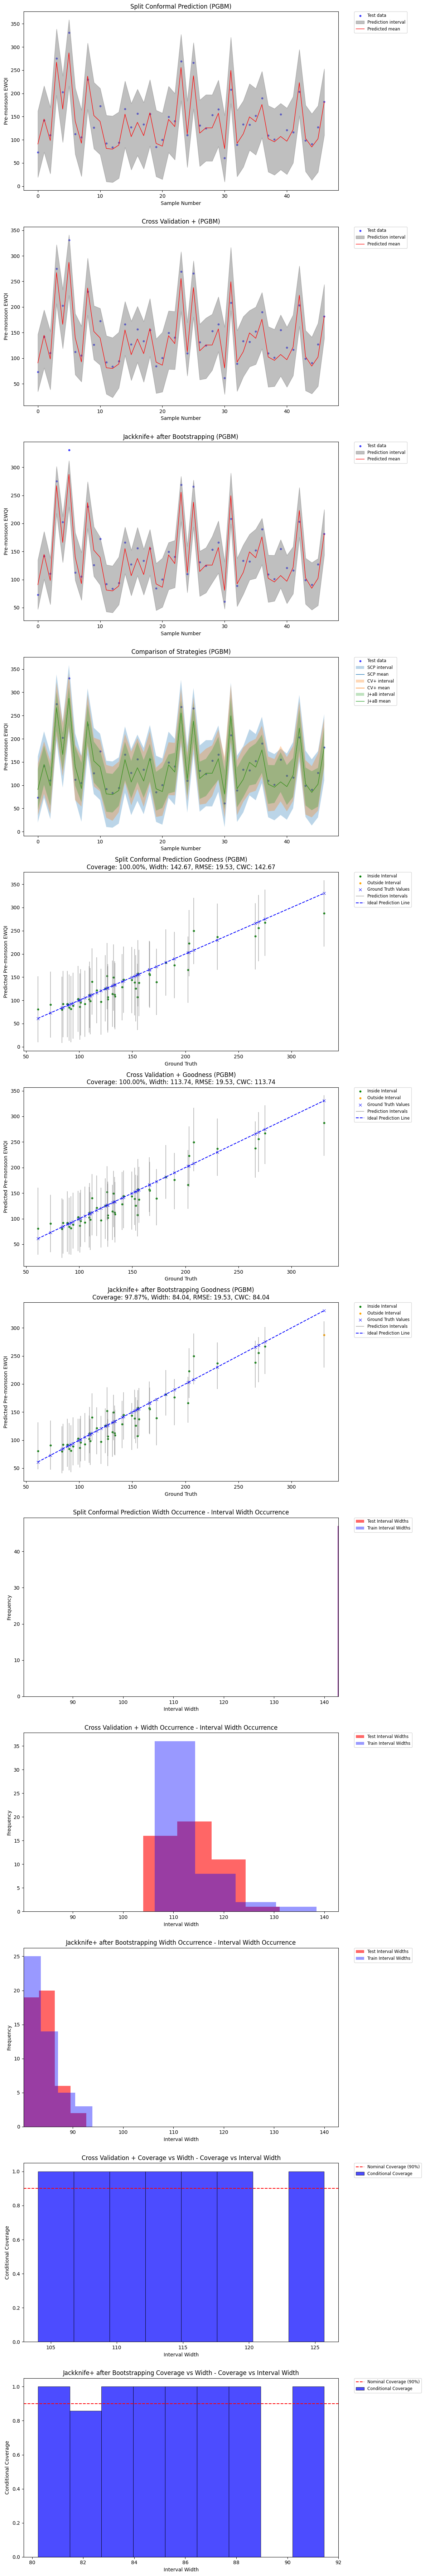

In [48]:
import os

def _ensure_parent_dir(path):
    parent = os.path.dirname(path)
    if parent:
        os.makedirs(parent, exist_ok=True)
    return path

import os
class validate:
    @staticmethod
    def coverage(int_pred, y_test):
        return {strat_name: np.mean((y_test >= int_pred[strat_name][:, 0]) & (y_test <= int_pred[strat_name][:, 1])) for strat_name in int_pred}
    @staticmethod
    def width(int_pred): # Corrected: Removed y_test argument as it's not defined and not used
        return {strat_name: np.mean(int_pred[strat_name][:, 1] - int_pred[strat_name][:, 0]) for strat_name in int_pred}
    @staticmethod
    def rmse(y_pred, y_test):
        return {strat_name: np.sqrt(mean_squared_error(y_test, y_pred[strat_name])) for strat_name in y_pred}
    @staticmethod
    def cwc(int_pred, y_test, miscoverage):
        widths = validate.width(int_pred)
        coverages = validate.coverage(int_pred, y_test)
        return {strat_name: widths[strat_name] * (1 + (coverages[strat_name] < (1 - miscoverage)) * (1 - coverages[strat_name])) for strat_name in int_pred}

    @staticmethod
    def cond_coverage(int_pred, y_test, num_bins=N_BINS):
        cond_coverages = {}
        for strat_name in int_pred:
            widths = int_pred[strat_name][:, 1] - int_pred[strat_name][:, 0]
            bin_edges = np.histogram_bin_edges(widths, bins=num_bins)
            digitized_widths = np.digitize(widths, bin_edges)
            strategy_cond_coverage = []
            for bin_num in range(1, num_bins + 1):
                indices_in_bin = np.where(digitized_widths == bin_num)[0]
                if len(indices_in_bin) > 0:
                    bin_coverage = np.mean((y_test[indices_in_bin] >= int_pred[strat_name][indices_in_bin, 0]) & (y_test[indices_in_bin] <= int_pred[strat_name][indices_in_bin, 1]))
                    strategy_cond_coverage.append(bin_coverage)
                else:
                    strategy_cond_coverage.append(np.nan) # or handle empty bins as needed
            cond_coverages[strat_name] = strategy_cond_coverage
        return cond_coverages


class visualize:
    @staticmethod
    def coverage(int_pred, y_test):
        return {strat_name: np.mean((y_test >= int_pred[strat_name][:, 0]) & (y_test.to_numpy() <= int_pred[strat_name][:, 1])) for strat_name in int_pred}
    @staticmethod
    def width(int_pred):
        return {strat_name: np.mean(int_pred[strat_name][:, 1] - int_pred[strat_name][:, 0]) for strat_name in int_pred}
    @staticmethod
    def rmse(y_pred, y_test):
        return {strat_name: np.sqrt(mean_squared_error(y_test, y_pred[strat_name])) for strat_name in y_pred}
    @staticmethod
    def cwc(int_pred, y_test, miscoverage):
        widths = visualize.width(int_pred)
        coverages = visualize.coverage(int_pred, y_test)
        return {strat_name: widths[strat_name] * (1 + (coverages[strat_name] < (1 - miscoverage)) * (1 - coverages[strat_name])) for strat_name in int_pred}
    @staticmethod
    def goodness(y_true, y_pred, y_pred_low, y_pred_up, coverage, width, rmse, cwc, ax=None, title="Goodness Plot"):
        if ax is None:
            fig, ax = plt.subplots()
        n_samples = len(y_true)
        y_true_np = y_true.ravel() # Ensure y_true is numpy array and flattened

        # Determine points inside and outside the interval
        inside_interval = (y_true_np >= y_pred_low) & (y_true_np <= y_pred_up)
        outside_interval = ~inside_interval

        # Plot points inside the interval in green
        ax.scatter(y_true_np[inside_interval], y_pred[inside_interval], color='green', s=10, label='Inside Interval')
        # Plot points outside the interval in orange
        ax.scatter(y_true_np[outside_interval], y_pred[outside_interval], color='orange', s=10, label='Outside Interval')

        # Plot all ground truth values as blue crosses
        ax.scatter(y_true_np, y_true_np, color='blue', marker='x', s=30, linewidths=0.7, label='Ground Truth Values')


        ax.vlines(y_true_np, y_pred_low, y_pred_up, color='gray', alpha=0.5, label='Prediction Intervals')
        ax.plot([min(y_true_np), max(y_true_np)], [min(y_true_np), max(y_true_np)], linestyle='--', color='blue', label='Ideal Prediction Line') # Changed label for clarity
        ax.set_xlabel('Ground Truth')
        ax.set_ylabel('Predictions')
        ax.set_title(f'{title}\nCoverage: {coverage*100:.2f}%, Width: {width:.2f}, RMSE: {rmse:.2f}, CWC: {cwc:.2f}')
        ax.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
        return ax

    @staticmethod
    def width_size_occurrence(int_pred, train_intervals, num_bins=N_BINS, ax=None, x_lim=None, title="Width Size Occurrence"):
        if ax is None:
            fig, ax = plt.subplots()

        # Calculate interval widths for test and train sets
        widths_test = np.abs(int_pred[:, 1] - int_pred[:, 0])
        widths_train = np.abs(train_intervals[:, 1] - train_intervals[:, 0])

        # Plot histograms for both train and test widths
        ax.hist(widths_test, bins=num_bins, alpha=0.6, label='Test Interval Widths', color='red')
        ax.hist(widths_train, bins=num_bins, alpha=0.4, label='Train Interval Widths', color='blue')


        if x_lim is not None:
            ax.set_xlim(x_lim)
        ax.set_xlabel('Interval Width')
        ax.set_ylabel('Occurrence (Frequency)')
        ax.set_title(f'{title} - Interval Width Occurrence')
        ax.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
        return ax

    @staticmethod
    def coverage_by_width(y_test, int_pred, miscoverage, cond_coverages, num_bins=N_BINS, ax=None, title="Coverage vs Width"):
        if ax is None:
            fig, ax = plt.subplots()

        widths = int_pred[:, 1] - int_pred[:, 0]
        bin_edges = np.histogram_bin_edges(widths, bins=num_bins)
        bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
        bin_width = bin_edges[1] - bin_edges[0]

        ax.bar(bin_centers, cond_coverages, width=bin_width, color='blue', alpha=0.7, edgecolor='black', linewidth=0.8, label='Conditional Coverage')
        ax.axhline(1 - miscoverage, color='red', linestyle='--', label=f'Nominal Coverage ({(1 - miscoverage)*100:.0f}%)')

        ax.set_xlabel('Interval Width')
        ax.set_ylabel('Conditional Coverage')
        ax.set_title(f'{title} - Coverage vs Interval Width')
        ax.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
        return ax



def conformal_predictions_MAPIE_PGBM(
    model_class,
    best_params,
    X_train,
    y_train,
    X_test,
    y_test,
    model_name,
    excel_file_path
):
    SEED = 123
    np.random.seed(SEED)
    MISCOVERAGE = ALPHA  # FIX M4: was 0.05
    warnings.filterwarnings("ignore")
    os.makedirs('output/regression', exist_ok=True)

    # Convert y_test to a NumPy array if it has to_numpy
    y_test_np = y_test.to_numpy() if hasattr(y_test, 'to_numpy') else y_test

    # Map method names to descriptive labels
    strategies_names = {
        'SCP': 'Split Conformal Prediction',
        'CV+': 'Cross Validation +',
        'J+aB': 'Jackknife+ after Bootstrapping',
    }

    # Corresponding parameters for each strategy
    strategies_params = {
        # FIX M3: split conformal = one model fitted on part of train, calibrated on the rest
        # (was method='base' with KFold(5), i.e. CV residuals, not split conformal)
        'SCP': {'method': 'base', 'cv': _split_cv(len(X_train), SEED)},  # FIX B9 (was ShuffleSplit, rejected by MAPIE 0.6)
        'CV+': {'method': "plus", 'cv': 10},
        'J+aB': {'method': "plus", 'cv': Subsample(n_resamplings=50, random_state=SEED)},  # FIX M3: J+aB uses 'plus' (was 'minmax')
    }

    # Create a base estimator object for each strategy
    base_estimators = {
        strat_name: model_class(**best_params) for strat_name in strategies_names
    }

    y_pred, int_pred = {}, {}
    y_pred_train, int_pred_train = {}, {} # Store train predictions and intervals
    # Fit & predict using MapieRegressor for each strategy
    for strat_name, base_estimator in base_estimators.items():
        mapie = MapieRegressor(base_estimator, **strategies_params[strat_name])
        mapie.fit(X_train, y_train)
        y_pred[strat_name], int_pred[strat_name] = mapie.predict(X_test, alpha=MISCOVERAGE)
        int_pred[strat_name] = int_pred[strat_name][:, :, 0]  # FIX M2: MAPIE returns (n, 2, n_alpha); keep (n, 2)
        y_pred_train[strat_name], int_pred_train[strat_name] = mapie.predict(X_train, alpha=MISCOVERAGE) # Predict on train set
        int_pred_train[strat_name] = int_pred_train[strat_name][:, :, 0]  # FIX M2: MAPIE returns (n, 2, n_alpha); keep (n, 2)


    # Calculate metrics
    coverages: dict = validate.coverage(int_pred, y_test)
    widths: dict = validate.width(int_pred)
    rmse_vals: dict = validate.rmse(y_pred, y_test)
    cwc_vals: dict = validate.cwc(int_pred, y_test, MISCOVERAGE)


    # Print metrics and prepare for plotting
    for strat_name in strategies_names.keys():
        if strat_name in y_pred:
            # Calculate RMSE (already calculated in validate.rmse, using rmse_vals now)
            rmse = rmse_vals[strat_name]

            # Calculate interval width (already calculated in validate.width, using widths now)
            interval_width = widths[strat_name]

            # Calculate coverage (already calculated in validate.coverage, using coverages now)
            coverage = coverages[strat_name]

            # Calculate CWC (already calculated in validate.cwc, using cwc_vals now)
            cwc = cwc_vals[strat_name]

            # Calculate SSC (Symmetric Scoring Criterion)
            ssc = np.mean((y_test - y_pred[strat_name])**2 + (int_pred[strat_name][:, 1] - int_pred[strat_name][:, 0])**2)

            print(f"Strategy: {strategies_names[strat_name]}")
            print(f"  RMSE: {rmse:.4f}")
            print(f"  Interval Width: {interval_width:.4f}")
            print(f"  Coverage: {coverage * 100:.2f}%")
            print(f"  CWC: {cwc:.4f}")
            print(f"  SSC: {ssc:.4f}")
            print()

    # Plot the intervals and predictions for each strategy
    _strategies = [_s for _s in strategies_names.keys() if _s != 'SCP']
    NUM_BINS: int = 10
    n_figs: int = len(strategies_names)*3 + 1 + len(_strategies)
    fig, axs = plt.subplots(nrows=n_figs, figsize=(12, 6 * n_figs))
    plot_index = 0

    # Individual strategy plots (original plots)
    for _i, strat_name in enumerate(strategies_names.keys()):
        if strat_name in y_pred:
            # Predicted intervals
            _y_pred_low = int_pred[strat_name][:, 0].ravel()
            _y_pred_up = int_pred[strat_name][:, 1].ravel()

            # Visualize
            sample_indices = np.arange(len(X_test))
            axs[plot_index].scatter(sample_indices, y_test_np, label='Test data', color='blue', s=10, alpha=0.7)
            axs[plot_index].fill_between(sample_indices, _y_pred_low, _y_pred_up,
                                            color='gray', alpha=0.5, label='Prediction interval')
            axs[plot_index].plot(sample_indices, y_pred[strat_name], color='red',
                                    label='Predicted mean', linewidth=1)
            axs[plot_index].set_title(f'{strategies_names[strat_name]} ({model_name})')
            axs[plot_index].set_xlabel('Sample Number')
            axs[plot_index].set_ylabel(f'{TARGET_LABEL}')
            axs[plot_index].legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
            plot_index += 1

    # Comparison subplot (moved after individual strategy plots)
    comparison_ax = axs[plot_index]
    sample_indices = np.arange(len(X_test))
    comparison_ax.scatter(sample_indices, y_test_np, label='Test data', color='blue', s=10, alpha=0.7)
    for strat_name in y_pred:
        _y_pred_low = int_pred[strat_name][:, 0].ravel()
        _y_pred_up = int_pred[strat_name][:, 1].ravel()
        comparison_ax.fill_between(sample_indices, _y_pred_low, _y_pred_up,
                                        alpha=0.3, label=f'{strat_name} interval')
        comparison_ax.plot(sample_indices, y_pred[strat_name],
                                label=f'{strat_name} mean', linewidth=1)

    comparison_ax.set_title(f'Comparison of Strategies ({model_name})')
    comparison_ax.set_xlabel('Sample Number')
    comparison_ax.set_ylabel(f'{TARGET_LABEL}')
    comparison_ax.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
    plot_index += 1


    # Goodness plots
    for _i, strat_name in enumerate(strategies_names.keys()):
        if strat_name in y_pred:
            _y_pred_low_goodness = int_pred[strat_name][:, 0].ravel()
            _y_pred_up_goodness = int_pred[strat_name][:, 1].ravel()

            axs[plot_index] = visualize.goodness(
                y_test, y_pred[strat_name],
                _y_pred_low_goodness,
                _y_pred_up_goodness,
                coverages[strat_name],
                widths[strat_name],
                rmse_vals[strat_name],
                cwc_vals[strat_name],
                ax=axs[plot_index],
                title=f'{strategies_names[strat_name]} Goodness ({model_name})', # Removed subsample
            )
            axs[plot_index].set_ylabel(f'Predicted {TARGET_LABEL}')
            plot_index += 1

    # Width Occurrence plots
    _x_max = (1+1e-3) * np.max([np.abs(int_pred[strat_name][:, 0] - int_pred[strat_name][:, 1]) for strat_name in strategies_names.keys() if strat_name in int_pred])
    _x_min = np.min([np.abs(int_pred[strat_name][:, 0] - int_pred[strat_name][:, 1]) for strat_name in strategies_names.keys() if strat_name in int_pred])

    for _i, strat_name in enumerate(strategies_names.keys()):
        if strat_name in y_pred:
            axs[plot_index] = visualize.width_size_occurrence(
                int_pred[strat_name],
                train_intervals=int_pred_train[strat_name],
                num_bins=N_BINS,
                ax=axs[plot_index],
                x_lim=[_x_min, _x_max],
                title=f'{strategies_names[strat_name]} Width Occurrence',
            )
            axs[plot_index].set_ylabel('Frequency')
            plot_index += 1

    # Coverage vs Width plots
    cond_coverages: dict = validate.cond_coverage(int_pred, y_test, num_bins=NUM_BINS)
    for _i, _strat in enumerate(_strategies):
        axs[plot_index] = visualize.coverage_by_width(
            y_test, int_pred[_strat], MISCOVERAGE,
            cond_coverages[_strat],
            num_bins=NUM_BINS,
            ax=axs[plot_index],
            title=f'{strategies_names[_strat]} Coverage vs Width',
        )
        plot_index += 1


    fig.tight_layout()

    # Save plots to Excel
    # Save plots to Excel
    with io.BytesIO() as buf:
        fig.savefig(buf, format='png', bbox_inches='tight')
        buf.seek(0)
        img = Image(PImage.open(buf)) # Use PIL to open from BytesIO

        # Load the workbook and add a new sheet
        workbook = load_workbook(_ensure_excel_file(excel_file_path))
        sheet_name = 'conformal_predictions_MAPIE'
        if sheet_name in workbook.sheetnames:
            sheet_name += '_new'
        worksheet = workbook.create_sheet(title=sheet_name)

        # Add the image to the worksheet
        worksheet.add_image(img, 'A1')

        #NEW: Save all predictions/intervals to one worksheet
        all_rows = []
        # Always use y_test_np for consistent array-ness
        for strat_name in y_pred:
            y_pred_np = y_pred[strat_name].ravel()
            ymin_np = int_pred[strat_name][:, 0].ravel()
            ymax_np = int_pred[strat_name][:, 1].ravel()
            width_np = ymax_np - ymin_np
            is_covered_np = ((y_test_np >= ymin_np) & (y_test_np <= ymax_np)).astype(int)
            residual_np = y_test_np - y_pred_np

            strat_df = pd.DataFrame({
                'sample_index': np.arange(len(y_pred_np)),
                'strategy': strat_name,
                'y_true': y_test_np,
                'y_pred': y_pred_np,
                'ymin': ymin_np,
                'ymax': ymax_np,
                'width': width_np,
                'is_covered': is_covered_np,
                'residual': residual_np
            })
            all_rows.append(strat_df)
        all_export_df = pd.concat(all_rows, axis=0, ignore_index=True)

        all_pred_sheet_name = 'all_pred_values'
        base_name = all_pred_sheet_name
        idx = 1
        while all_pred_sheet_name in workbook.sheetnames:
            all_pred_sheet_name = f'{base_name}_new{idx}'
            idx += 1

        worksheet2 = workbook.create_sheet(title=all_pred_sheet_name)

        for j, col_name in enumerate(all_export_df.columns, 1):
            worksheet2.cell(row=1, column=j, value=col_name)
        for i, row in all_export_df.iterrows():
            for j, value in enumerate(row, 1):
                worksheet2.cell(row=i+2, column=j, value=float(value) if isinstance(value, np.generic) else value)

        # Save the workbook
        _ensure_parent_dir(excel_file_path)
        workbook.save(_ensure_parent_dir(excel_file_path))



# Example call (assuming best_params, X_train, y_train, X_test, y_test are defined elsewhere)
conformal_predictions_MAPIE_PGBM(
    model_class=PGBMWrapper,
    best_params=best_params,
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
    model_name="PGBM",
    excel_file_path="./drive/MyDrive/Regression/water_quality_ewqi_uncertainty_analysis/conformal_predictions_mapie_puncc/PGBM.xlsx"
)

In [49]:
import os

def _ensure_parent_dir(path):
    parent = os.path.dirname(path)
    if parent:
        os.makedirs(parent, exist_ok=True)
    return path

import os
def conformal_predictions_PUNCC_PGBM(
    X_train,
    y_train,
    X_test,
    y_test,
    best_scores_autosampler,
    model_class,
    excel_file_path=None,
    model_params=None,
    alpha=ALPHA  # FIX M4: was 0.1
):
    if model_params is None:
        if model_class.__name__ == 'PGBMWrapper':
            model_params = get_best_model_params(best_scores_autosampler, 'PGBM')
        else:
            model_params = {}

    # Initialize model
    try:
        model = model_class(**model_params)
    except TypeError as e:
        print(f"Error initializing model {model_class.__name__}: {e}")
        return

    # Convert to NumPy arrays if needed
    y_train_np = y_train.to_numpy() if isinstance(y_train, pd.Series) else y_train
    model.fit(X_train, y_train_np)

    y_test_np = y_test.to_numpy() if isinstance(y_test, pd.Series) else y_test

    def evaluate_cp(X_test_eval, y_test_eval, model_cp, alpha_val):
        X_test_np = X_test_eval.to_numpy() if isinstance(X_test_eval, pd.DataFrame) else np.array(X_test_eval)
        y_pred, y_pred_lower, y_pred_upper = model_cp.predict(X_test_np, alpha=alpha_val)
        sharpness = regression_sharpness(y_pred_lower, y_pred_upper)
        coverage = regression_mean_coverage(y_test_eval, y_pred_lower, y_pred_upper)
        return y_pred, y_pred_lower, y_pred_upper, sharpness, coverage

    # Base predictor setup
    base_predictor = BasePredictor(model, is_trained=True)

    # SplitCP
    splitcp = SplitCP(base_predictor, train=True, random_state=0)
    splitcp.fit(X=X_train, y=y_train_np, fit_ratio=0.5)

    y_pred_sc, y_lower_sc, y_upper_sc, sharpness_sc, coverage_sc = evaluate_cp(X_test, y_test_np, splitcp, alpha)

    # CVPlus
    cvplus = CVPlus(base_predictor, K=5, random_state=0)
    cvplus.fit(X=X_train, y=y_train_np)
    y_pred, y_lower_cv, y_upper_cv, sharpness_cv, coverage_cv = evaluate_cp(X_test, y_test_np, cvplus, alpha)

    # CQR
    X_fit, X_calib, y_fit, y_calib = train_test_split(X_train, y_train_np, test_size=0.5, random_state=0)
    upper_quantile_model = QuantileModel(model_class, model_params, 1 - alpha / 2)  # FIX M1: was model_class(**model_params)
    lower_quantile_model = QuantileModel(model_class, model_params, alpha / 2)      # FIX M1: was model_class(**model_params)
    upper_quantile_model.fit(X_fit, y_fit)
    lower_quantile_model.fit(X_fit, y_fit)
    dualpredictor = DualPredictor([lower_quantile_model, upper_quantile_model], is_trained=[True, True])
    cqr = CQR(dualpredictor, train=False)
    cqr.fit(X_calib=X_calib, y_calib=y_calib)
    y_pred_cqr, y_lower_cqr, y_upper_cqr, sharpness_cqr, coverage_cqr = evaluate_cp(X_test, y_test_np, cqr, alpha)
    y_pred_cqr = 0.5 * (y_lower_cqr + y_upper_cqr)
    print(f"SplitCP - Average prediction intervals width (sharpness): {sharpness_sc:.3f}")
    print(f"SplitCP - Average coverage: {coverage_sc*100:.3f}%")
    print(f"CVPlus - Average prediction intervals width (sharpness): {sharpness_cv:.3f}")
    print(f"CVPlus - Average coverage: {coverage_cv*100:.3f}%")
    print(f"CQR - Average prediction intervals width (sharpness): {sharpness_cqr:.3f}")
    print(f"CQR - Average coverage: {coverage_cqr*100:.3f}%")


    # Plotting
    fig, axs = plt.subplots(3, 1, figsize=(10, 18))
    sample_indices = np.arange(len(y_test_np))

    # Plot results for each method
    for idx, (y_pred, y_lower, y_upper, title) in enumerate([
        (y_pred_sc, y_lower_sc, y_upper_sc, 'SplitCP'),
        (y_pred_sc, y_lower_cv, y_upper_cv, 'CVPlus'),
        (y_pred_cqr, y_lower_cqr, y_upper_cqr, 'CQR')
    ]):
        axs[idx].scatter(sample_indices, y_test_np, label='True', color='blue', s=10, alpha=0.7)
        axs[idx].fill_between(sample_indices, y_lower, y_upper, color='gray', alpha=0.5, label='Prediction interval')
        axs[idx].plot(sample_indices, y_pred, color='red', label='Predicted mean', linewidth=1)
        axs[idx].set_title(f'{title}: Prediction Intervals with Conformal Prediction')
        axs[idx].set_xlabel('Sample Number')
        axs[idx].set_ylabel(f'{TARGET_LABEL}')
        axs[idx].legend(fontsize='small')

    plt.tight_layout()

    # --- Collect values for export, grouped by method ---
    results_dict = {
        'SplitCP_true': np.asarray(y_test).reshape(-1),
        'SplitCP_pred': np.asarray(y_pred_sc).reshape(-1),
        'SplitCP_lower': np.asarray(y_lower_sc).reshape(-1),
        'SplitCP_upper': np.asarray(y_upper_sc).reshape(-1),

        'CVPlus_true': np.asarray(y_test).reshape(-1),
        'CVPlus_pred': np.asarray(y_pred_sc).reshape(-1),
        'CVPlus_lower': np.asarray(y_lower_cv).reshape(-1),
        'CVPlus_upper': np.asarray(y_upper_cv).reshape(-1),

        'CQR_true': np.asarray(y_test).reshape(-1),
        'CQR_pred': np.asarray(y_pred_cqr).reshape(-1),
        'CQR_lower': np.asarray(y_lower_cqr).reshape(-1),
        'CQR_upper': np.asarray(y_upper_cqr).reshape(-1),
    }

    if excel_file_path:
        save_plot_to_excel(fig, excel_file_path, 'conformal_predictions_PUNCC')
        save_values_to_excel(results_dict, excel_file_path, 'conformal_predictions_PUNCC_values')

    plt.close(fig)

def save_plot_to_excel(fig, excel_file_path, sheet_name):
    with io.BytesIO() as buf:
        fig.savefig(buf, format='png')
        buf.seek(0)
        img = Image(buf)

        # Load the workbook and add a new sheet
        workbook = load_workbook(_ensure_excel_file(excel_file_path))
        if sheet_name in workbook.sheetnames:
            base_name = sheet_name
            i = 1
            while sheet_name in workbook.sheetnames:
                sheet_name = f"{base_name}_{i}"
                i += 1
        worksheet = workbook.create_sheet(title=sheet_name)

        # Add the image to the worksheet
        worksheet.add_image(img, 'A1')

        # Save the workbook
        _ensure_parent_dir(excel_file_path)
        workbook.save(_ensure_parent_dir(excel_file_path))

def save_values_to_excel(results_dict, excel_file_path, sheet_name):
    # Convert the dictionary to a DataFrame (columns will be in the order of insertion)
    df = pd.DataFrame(results_dict)
    # Load the workbook
    workbook = load_workbook(_ensure_excel_file(excel_file_path))
    # Ensure unique sheet name
    base_name = sheet_name
    i = 1
    while sheet_name in workbook.sheetnames:
        sheet_name = f"{base_name}_{i}"
        i += 1
    # Write DataFrame to a new sheet
    worksheet = workbook.create_sheet(title=sheet_name)
    for r_idx, row in enumerate(dataframe_to_rows(df, index=False, header=True), 1):
        for c_idx, value in enumerate(row, 1):
            worksheet.cell(row=r_idx, column=c_idx, value=value)
    # Save the workbook
    _ensure_parent_dir(excel_file_path)
    workbook.save(_ensure_parent_dir(excel_file_path))

# Example usage (assuming X_train, y_train, X_test, y_test, best_scores_autosampler exist):
conformal_predictions_PUNCC_PGBM(
    X_train, y_train,
    X_test, y_test,
    best_scores_autosampler=best_scores_autosampler,
    model_class=PGBMWrapper,
    excel_file_path="./drive/MyDrive/Regression/water_quality_ewqi_uncertainty_analysis/conformal_predictions_mapie_puncc/PGBM.xlsx",
    alpha=0.1
)


Training on CPU
Estimator 0/300, Train metric: 55.0218
Estimator 1/300, Train metric: 53.3739
Estimator 2/300, Train metric: 52.0749
Estimator 3/300, Train metric: 50.5340
Estimator 4/300, Train metric: 48.7228
Estimator 5/300, Train metric: 47.0657
Estimator 6/300, Train metric: 46.0698
Estimator 7/300, Train metric: 44.7027
Estimator 8/300, Train metric: 43.7969
Estimator 9/300, Train metric: 42.3529
Estimator 10/300, Train metric: 41.1388
Estimator 11/300, Train metric: 39.9451
Estimator 12/300, Train metric: 39.3936
Estimator 13/300, Train metric: 38.5708
Estimator 14/300, Train metric: 37.4268
Estimator 15/300, Train metric: 36.2130
Estimator 16/300, Train metric: 35.8212
Estimator 17/300, Train metric: 35.3588
Estimator 18/300, Train metric: 34.8089
Estimator 19/300, Train metric: 34.4374
Estimator 20/300, Train metric: 34.0438
Estimator 21/300, Train metric: 33.6476
Estimator 22/300, Train metric: 32.8975
Estimator 23/300, Train metric: 32.2363
Estimator 24/300, Train metric: 31

Estimator 42/300, Train metric: 21.3036
Estimator 43/300, Train metric: 21.0520
Estimator 44/300, Train metric: 20.6351
Estimator 45/300, Train metric: 20.4684
Estimator 46/300, Train metric: 20.1000
Estimator 47/300, Train metric: 19.8026
Estimator 48/300, Train metric: 19.5589
Estimator 49/300, Train metric: 19.4191
Estimator 50/300, Train metric: 19.0989
Estimator 51/300, Train metric: 18.7039
Estimator 52/300, Train metric: 18.7178
Estimator 53/300, Train metric: 18.5688
Estimator 54/300, Train metric: 18.3391
Estimator 55/300, Train metric: 17.9783
Estimator 56/300, Train metric: 17.8861
Estimator 57/300, Train metric: 17.7476
Estimator 58/300, Train metric: 17.4496
Estimator 59/300, Train metric: 17.1360
Estimator 60/300, Train metric: 16.9987
Estimator 61/300, Train metric: 16.7382
Estimator 62/300, Train metric: 16.5740
Estimator 63/300, Train metric: 16.3673
Estimator 64/300, Train metric: 16.3097
Estimator 65/300, Train metric: 16.0251
Estimator 66/300, Train metric: 15.7774


Estimator 86/300, Train metric: 13.0907
Estimator 87/300, Train metric: 13.0373
Estimator 88/300, Train metric: 13.0103
Estimator 89/300, Train metric: 12.8905
Estimator 90/300, Train metric: 12.8355
Estimator 91/300, Train metric: 12.7364
Estimator 92/300, Train metric: 12.5994
Estimator 93/300, Train metric: 12.4648
Estimator 94/300, Train metric: 12.2250
Estimator 95/300, Train metric: 12.0125
Estimator 96/300, Train metric: 11.9530
Estimator 97/300, Train metric: 11.9207
Estimator 98/300, Train metric: 11.8422
Estimator 99/300, Train metric: 11.7715
Estimator 100/300, Train metric: 11.7421
Estimator 101/300, Train metric: 11.6483
Estimator 102/300, Train metric: 11.4578
Estimator 103/300, Train metric: 11.3104
Estimator 104/300, Train metric: 11.1709
Estimator 105/300, Train metric: 11.1320
Estimator 106/300, Train metric: 11.1323
Estimator 107/300, Train metric: 11.1133
Estimator 108/300, Train metric: 11.0399
Estimator 109/300, Train metric: 10.8530
Estimator 110/300, Train metri

Estimator 128/300, Train metric: 9.8036
Estimator 129/300, Train metric: 9.6728
Estimator 130/300, Train metric: 9.6110
Estimator 131/300, Train metric: 9.5791
Estimator 132/300, Train metric: 9.5569
Estimator 133/300, Train metric: 9.5385
Estimator 134/300, Train metric: 9.4700
Estimator 135/300, Train metric: 9.4091
Estimator 136/300, Train metric: 9.4051
Estimator 137/300, Train metric: 9.2752
Estimator 138/300, Train metric: 9.1582
Estimator 139/300, Train metric: 9.1144
Estimator 140/300, Train metric: 9.1211
Estimator 141/300, Train metric: 9.0928
Estimator 142/300, Train metric: 9.0618
Estimator 143/300, Train metric: 9.0502
Estimator 144/300, Train metric: 8.9818
Estimator 145/300, Train metric: 8.9173
Estimator 146/300, Train metric: 8.8772
Estimator 147/300, Train metric: 8.7642
Estimator 148/300, Train metric: 8.7541
Estimator 149/300, Train metric: 8.7641
Estimator 150/300, Train metric: 8.7435
Estimator 151/300, Train metric: 8.6394
Estimator 152/300, Train metric: 8.6179


Estimator 167/300, Train metric: 8.0945
Estimator 168/300, Train metric: 7.9866
Estimator 169/300, Train metric: 7.9883
Estimator 170/300, Train metric: 7.9698
Estimator 171/300, Train metric: 7.9719
Estimator 172/300, Train metric: 7.9138
Estimator 173/300, Train metric: 7.8723
Estimator 174/300, Train metric: 7.8243
Estimator 175/300, Train metric: 7.8278
Estimator 176/300, Train metric: 7.8433
Estimator 177/300, Train metric: 7.8214
Estimator 178/300, Train metric: 7.8264
Estimator 179/300, Train metric: 7.7773
Estimator 180/300, Train metric: 7.6972
Estimator 181/300, Train metric: 7.6182
Estimator 182/300, Train metric: 7.5688
Estimator 183/300, Train metric: 7.5420
Estimator 184/300, Train metric: 7.4684
Estimator 185/300, Train metric: 7.4722
Estimator 186/300, Train metric: 7.4772
Estimator 187/300, Train metric: 7.3982
Estimator 188/300, Train metric: 7.3940
Estimator 189/300, Train metric: 7.3914
Estimator 190/300, Train metric: 7.3487
Estimator 191/300, Train metric: 7.2955


Estimator 207/300, Train metric: 7.0047
Estimator 208/300, Train metric: 6.9527
Estimator 209/300, Train metric: 6.9280
Estimator 210/300, Train metric: 6.9172
Estimator 211/300, Train metric: 6.9223
Estimator 212/300, Train metric: 6.8699
Estimator 213/300, Train metric: 6.8710
Estimator 214/300, Train metric: 6.8053
Estimator 215/300, Train metric: 6.7838
Estimator 216/300, Train metric: 6.7737
Estimator 217/300, Train metric: 6.7405
Estimator 218/300, Train metric: 6.6536
Estimator 219/300, Train metric: 6.6429
Estimator 220/300, Train metric: 6.6378
Estimator 221/300, Train metric: 6.6014
Estimator 222/300, Train metric: 6.6011
Estimator 223/300, Train metric: 6.6056
Estimator 224/300, Train metric: 6.5337
Estimator 225/300, Train metric: 6.4972
Estimator 226/300, Train metric: 6.4960
Estimator 227/300, Train metric: 6.4901
Estimator 228/300, Train metric: 6.4128
Estimator 229/300, Train metric: 6.3822
Estimator 230/300, Train metric: 6.3718
Estimator 231/300, Train metric: 6.3704


... (40 outputs left out)

Estimator 26/300, Train metric: 41.7247
Estimator 27/300, Train metric: 41.2663
Estimator 28/300, Train metric: 40.4773
Estimator 29/300, Train metric: 40.0319
Estimator 30/300, Train metric: 39.1866
Estimator 31/300, Train metric: 37.9978
Estimator 32/300, Train metric: 37.2776
Estimator 33/300, Train metric: 37.2566
Estimator 34/300, Train metric: 36.9338
Estimator 35/300, Train metric: 35.7546
Estimator 36/300, Train metric: 35.4125
Estimator 37/300, Train metric: 34.6037
Estimator 38/300, Train metric: 33.6837
Estimator 39/300, Train metric: 33.0557
Estimator 40/300, Train metric: 33.0604
Estimator 41/300, Train metric: 32.5500
Estimator 42/300, Train metric: 32.3467
Estimator 43/300, Train metric: 32.1785
Estimator 44/300, Train metric: 31.7485
Estimator 45/300, Train metric: 30.7823
Estimator 46/300, Train metric: 30.6431
Estimator 47/300, Train metric: 30.0846
Estimator 48/300, Train metric: 29.7626
Estimator 49/300, Train metric: 29.1567
Estimator 50/300, Train metric: 28.8576


Estimator 114/300, Train metric: 16.1291
Estimator 115/300, Train metric: 15.9347
Estimator 116/300, Train metric: 15.9847
Estimator 117/300, Train metric: 15.9290
Estimator 118/300, Train metric: 15.8916
Estimator 119/300, Train metric: 15.8821
Estimator 120/300, Train metric: 15.7807
Estimator 121/300, Train metric: 15.6987
Estimator 122/300, Train metric: 15.5268
Estimator 123/300, Train metric: 15.4734
Estimator 124/300, Train metric: 15.2542
Estimator 125/300, Train metric: 15.0499
Estimator 126/300, Train metric: 14.8499
Estimator 127/300, Train metric: 14.6567
Estimator 128/300, Train metric: 14.4919
Estimator 129/300, Train metric: 14.5078
Estimator 130/300, Train metric: 14.4383
Estimator 131/300, Train metric: 14.3960
Estimator 132/300, Train metric: 14.4066
Estimator 133/300, Train metric: 14.4242
Estimator 134/300, Train metric: 14.3289
Estimator 135/300, Train metric: 14.2053
Estimator 136/300, Train metric: 14.0533
Estimator 137/300, Train metric: 13.9700
Estimator 138/30

Estimator 196/300, Train metric: 10.4401
Estimator 197/300, Train metric: 10.4436
Estimator 198/300, Train metric: 10.4115
Estimator 199/300, Train metric: 10.3364
Estimator 200/300, Train metric: 10.3427
Estimator 201/300, Train metric: 10.3067
Estimator 202/300, Train metric: 10.3084
Estimator 203/300, Train metric: 10.2303
Estimator 204/300, Train metric: 10.2241
Estimator 205/300, Train metric: 10.2093
Estimator 206/300, Train metric: 10.2049
Estimator 207/300, Train metric: 10.2045
Estimator 208/300, Train metric: 10.1163
Estimator 209/300, Train metric: 10.0614
Estimator 210/300, Train metric: 10.0470
Estimator 211/300, Train metric: 10.0322
Estimator 212/300, Train metric: 10.0487
Estimator 213/300, Train metric: 10.0648
Estimator 214/300, Train metric: 9.9443
Estimator 215/300, Train metric: 9.9480
Estimator 216/300, Train metric: 9.9726
Estimator 217/300, Train metric: 9.9568
Estimator 218/300, Train metric: 9.9629
Estimator 219/300, Train metric: 9.9555
Estimator 220/300, Tra

Estimator 274/300, Train metric: 7.6952
Estimator 275/300, Train metric: 7.6203
Estimator 276/300, Train metric: 7.5502
Estimator 277/300, Train metric: 7.5412
Estimator 278/300, Train metric: 7.5376
Estimator 279/300, Train metric: 7.5414
Estimator 280/300, Train metric: 7.5473
Estimator 281/300, Train metric: 7.4398
Estimator 282/300, Train metric: 7.4183
Estimator 283/300, Train metric: 7.4202
Estimator 284/300, Train metric: 7.3266
Estimator 285/300, Train metric: 7.3333
Estimator 286/300, Train metric: 7.3288
Estimator 287/300, Train metric: 7.3348
Estimator 288/300, Train metric: 7.2816
Estimator 289/300, Train metric: 7.2206
Estimator 290/300, Train metric: 7.2197
Estimator 291/300, Train metric: 7.2254
Estimator 292/300, Train metric: 7.2397
Estimator 293/300, Train metric: 7.1687
Estimator 294/300, Train metric: 7.1252
Estimator 295/300, Train metric: 7.0812
Estimator 296/300, Train metric: 7.0874
Estimator 297/300, Train metric: 7.0538
Estimator 298/300, Train metric: 7.0109


In [50]:
best_params = get_best_model_params(best_scores_autosampler, 'PGBM')
prediction_MAPIE_analysis(X_train, y_train, X_test, y_test, PGBMWrapper, best_params,"./drive/MyDrive/Regression/water_quality_ewqi_uncertainty_analysis/conformal_predictions_mapie_puncc/PGBM.xlsx", "PGBM Prediction Intervals")

Training on CPU
Estimator 0/300, Train metric: 55.0218
Estimator 1/300, Train metric: 53.3739
Estimator 2/300, Train metric: 52.0749
Estimator 3/300, Train metric: 50.5340
Estimator 4/300, Train metric: 48.7228
Estimator 5/300, Train metric: 47.0657
Estimator 6/300, Train metric: 46.0698
Estimator 7/300, Train metric: 44.7027
Estimator 8/300, Train metric: 43.7969
Estimator 9/300, Train metric: 42.3529
Estimator 10/300, Train metric: 41.1388
Estimator 11/300, Train metric: 39.9451
Estimator 12/300, Train metric: 39.3936
Estimator 13/300, Train metric: 38.5708
Estimator 14/300, Train metric: 37.4268
Estimator 15/300, Train metric: 36.2130
Estimator 16/300, Train metric: 35.8212
Estimator 17/300, Train metric: 35.3588
Estimator 18/300, Train metric: 34.8089
Estimator 19/300, Train metric: 34.4374
Estimator 20/300, Train metric: 34.0438
Estimator 21/300, Train metric: 33.6476
Estimator 22/300, Train metric: 32.8975
Estimator 23/300, Train metric: 32.2363
Estimator 24/300, Train metric: 31

Estimator 42/300, Train metric: 21.3036
Estimator 43/300, Train metric: 21.0520
Estimator 44/300, Train metric: 20.6351
Estimator 45/300, Train metric: 20.4684
Estimator 46/300, Train metric: 20.1000
Estimator 47/300, Train metric: 19.8026
Estimator 48/300, Train metric: 19.5589
Estimator 49/300, Train metric: 19.4191
Estimator 50/300, Train metric: 19.0989
Estimator 51/300, Train metric: 18.7039
Estimator 52/300, Train metric: 18.7178
Estimator 53/300, Train metric: 18.5688
Estimator 54/300, Train metric: 18.3391
Estimator 55/300, Train metric: 17.9783
Estimator 56/300, Train metric: 17.8861
Estimator 57/300, Train metric: 17.7476
Estimator 58/300, Train metric: 17.4496
Estimator 59/300, Train metric: 17.1360
Estimator 60/300, Train metric: 16.9987
Estimator 61/300, Train metric: 16.7382
Estimator 62/300, Train metric: 16.5740
Estimator 63/300, Train metric: 16.3673
Estimator 64/300, Train metric: 16.3097
Estimator 65/300, Train metric: 16.0251
Estimator 66/300, Train metric: 15.7774


Estimator 86/300, Train metric: 13.0907
Estimator 87/300, Train metric: 13.0373
Estimator 88/300, Train metric: 13.0103
Estimator 89/300, Train metric: 12.8905
Estimator 90/300, Train metric: 12.8355
Estimator 91/300, Train metric: 12.7364
Estimator 92/300, Train metric: 12.5994
Estimator 93/300, Train metric: 12.4648
Estimator 94/300, Train metric: 12.2250
Estimator 95/300, Train metric: 12.0125
Estimator 96/300, Train metric: 11.9530
Estimator 97/300, Train metric: 11.9207
Estimator 98/300, Train metric: 11.8422
Estimator 99/300, Train metric: 11.7715
Estimator 100/300, Train metric: 11.7421
Estimator 101/300, Train metric: 11.6483
Estimator 102/300, Train metric: 11.4578
Estimator 103/300, Train metric: 11.3104
Estimator 104/300, Train metric: 11.1709
Estimator 105/300, Train metric: 11.1320
Estimator 106/300, Train metric: 11.1323
Estimator 107/300, Train metric: 11.1133
Estimator 108/300, Train metric: 11.0399
Estimator 109/300, Train metric: 10.8530
Estimator 110/300, Train metri

Estimator 128/300, Train metric: 9.8036
Estimator 129/300, Train metric: 9.6728
Estimator 130/300, Train metric: 9.6110
Estimator 131/300, Train metric: 9.5791
Estimator 132/300, Train metric: 9.5569
Estimator 133/300, Train metric: 9.5385
Estimator 134/300, Train metric: 9.4700
Estimator 135/300, Train metric: 9.4091
Estimator 136/300, Train metric: 9.4051
Estimator 137/300, Train metric: 9.2752
Estimator 138/300, Train metric: 9.1582
Estimator 139/300, Train metric: 9.1144
Estimator 140/300, Train metric: 9.1211
Estimator 141/300, Train metric: 9.0928
Estimator 142/300, Train metric: 9.0618
Estimator 143/300, Train metric: 9.0502
Estimator 144/300, Train metric: 8.9818
Estimator 145/300, Train metric: 8.9173
Estimator 146/300, Train metric: 8.8772
Estimator 147/300, Train metric: 8.7642
Estimator 148/300, Train metric: 8.7541
Estimator 149/300, Train metric: 8.7641
Estimator 150/300, Train metric: 8.7435
Estimator 151/300, Train metric: 8.6394
Estimator 152/300, Train metric: 8.6179


Estimator 168/300, Train metric: 7.9866
Estimator 169/300, Train metric: 7.9883
Estimator 170/300, Train metric: 7.9698
Estimator 171/300, Train metric: 7.9719
Estimator 172/300, Train metric: 7.9138
Estimator 173/300, Train metric: 7.8723
Estimator 174/300, Train metric: 7.8243
Estimator 175/300, Train metric: 7.8278
Estimator 176/300, Train metric: 7.8433
Estimator 177/300, Train metric: 7.8214
Estimator 178/300, Train metric: 7.8264
Estimator 179/300, Train metric: 7.7773
Estimator 180/300, Train metric: 7.6972
Estimator 181/300, Train metric: 7.6182
Estimator 182/300, Train metric: 7.5688
Estimator 183/300, Train metric: 7.5420
Estimator 184/300, Train metric: 7.4684
Estimator 185/300, Train metric: 7.4722
Estimator 186/300, Train metric: 7.4772
Estimator 187/300, Train metric: 7.3982
Estimator 188/300, Train metric: 7.3940
Estimator 189/300, Train metric: 7.3914
Estimator 190/300, Train metric: 7.3487
Estimator 191/300, Train metric: 7.2955
Estimator 192/300, Train metric: 7.2783


Estimator 210/300, Train metric: 6.9172
Estimator 211/300, Train metric: 6.9223
Estimator 212/300, Train metric: 6.8699
Estimator 213/300, Train metric: 6.8710
Estimator 214/300, Train metric: 6.8053
Estimator 215/300, Train metric: 6.7838
Estimator 216/300, Train metric: 6.7737
Estimator 217/300, Train metric: 6.7405
Estimator 218/300, Train metric: 6.6536
Estimator 219/300, Train metric: 6.6429
Estimator 220/300, Train metric: 6.6378
Estimator 221/300, Train metric: 6.6014
Estimator 222/300, Train metric: 6.6011
Estimator 223/300, Train metric: 6.6056
Estimator 224/300, Train metric: 6.5337
Estimator 225/300, Train metric: 6.4972
Estimator 226/300, Train metric: 6.4960
Estimator 227/300, Train metric: 6.4901
Estimator 228/300, Train metric: 6.4128
Estimator 229/300, Train metric: 6.3822
Estimator 230/300, Train metric: 6.3718
Estimator 231/300, Train metric: 6.3704
Estimator 232/300, Train metric: 6.3162
Estimator 233/300, Train metric: 6.3248
Estimator 234/300, Train metric: 6.3246


... (292 outputs left out)

Estimator 138/300, Train metric: 7.3796
Estimator 139/300, Train metric: 7.3430
Estimator 140/300, Train metric: 7.2461
Estimator 141/300, Train metric: 7.1353
Estimator 142/300, Train metric: 7.0558
Estimator 143/300, Train metric: 6.9610
Estimator 144/300, Train metric: 6.8841
Estimator 145/300, Train metric: 6.7923
Estimator 146/300, Train metric: 6.7932
Estimator 147/300, Train metric: 6.6687
Estimator 148/300, Train metric: 6.6907
Estimator 149/300, Train metric: 6.6089
Estimator 150/300, Train metric: 6.5364
Estimator 151/300, Train metric: 6.5532
Estimator 152/300, Train metric: 6.5252
Estimator 153/300, Train metric: 6.4938
Estimator 154/300, Train metric: 6.4539
Estimator 155/300, Train metric: 6.4274
Estimator 156/300, Train metric: 6.3253
Estimator 157/300, Train metric: 6.2892
Estimator 158/300, Train metric: 6.1912
Estimator 159/300, Train metric: 6.0568
Estimator 160/300, Train metric: 5.9704
Estimator 161/300, Train metric: 5.9575
Estimator 162/300, Train metric: 5.8778


Estimator 180/300, Train metric: 5.0187
Estimator 181/300, Train metric: 4.9574
Estimator 182/300, Train metric: 4.8688
Estimator 183/300, Train metric: 4.8039
Estimator 184/300, Train metric: 4.7764
Estimator 185/300, Train metric: 4.7466
Estimator 186/300, Train metric: 4.7199
Estimator 187/300, Train metric: 4.7054
Estimator 188/300, Train metric: 4.6936
Estimator 189/300, Train metric: 4.7079
Estimator 190/300, Train metric: 4.6445
Estimator 191/300, Train metric: 4.6300
Estimator 192/300, Train metric: 4.6184
Estimator 193/300, Train metric: 4.6228
Estimator 194/300, Train metric: 4.5858
Estimator 195/300, Train metric: 4.5862
Estimator 196/300, Train metric: 4.5678
Estimator 197/300, Train metric: 4.4868
Estimator 198/300, Train metric: 4.4481
Estimator 199/300, Train metric: 4.3979
Estimator 200/300, Train metric: 4.4059
Estimator 201/300, Train metric: 4.3601
Estimator 202/300, Train metric: 4.3144
Estimator 203/300, Train metric: 4.3056
Estimator 204/300, Train metric: 4.2388


Estimator 225/300, Train metric: 3.6049
Estimator 226/300, Train metric: 3.5737
Estimator 227/300, Train metric: 3.5574
Estimator 228/300, Train metric: 3.5489
Estimator 229/300, Train metric: 3.5549
Estimator 230/300, Train metric: 3.5608
Estimator 231/300, Train metric: 3.4897
Estimator 232/300, Train metric: 3.4747
Estimator 233/300, Train metric: 3.4807
Estimator 234/300, Train metric: 3.4426
Estimator 235/300, Train metric: 3.4247
Estimator 236/300, Train metric: 3.3845
Estimator 237/300, Train metric: 3.3757
Estimator 238/300, Train metric: 3.3328
Estimator 239/300, Train metric: 3.2892
Estimator 240/300, Train metric: 3.2643
Estimator 241/300, Train metric: 3.2581
Estimator 242/300, Train metric: 3.1896
Estimator 243/300, Train metric: 3.1719
Estimator 244/300, Train metric: 3.1627
Estimator 245/300, Train metric: 3.1122
Estimator 246/300, Train metric: 3.0869
Estimator 247/300, Train metric: 3.0778
Estimator 248/300, Train metric: 3.0639
Estimator 249/300, Train metric: 3.0211


Estimator 269/300, Train metric: 2.6229
Estimator 270/300, Train metric: 2.6021
Estimator 271/300, Train metric: 2.5556
Estimator 272/300, Train metric: 2.5482
Estimator 273/300, Train metric: 2.5473
Estimator 274/300, Train metric: 2.5217
Estimator 275/300, Train metric: 2.4930
Estimator 276/300, Train metric: 2.4746
Estimator 277/300, Train metric: 2.4546
Estimator 278/300, Train metric: 2.4477
Estimator 279/300, Train metric: 2.4203
Estimator 280/300, Train metric: 2.4093
Estimator 281/300, Train metric: 2.3939
Estimator 282/300, Train metric: 2.3795
Estimator 283/300, Train metric: 2.3488
Estimator 284/300, Train metric: 2.3465
Estimator 285/300, Train metric: 2.3269
Estimator 286/300, Train metric: 2.2975
Estimator 287/300, Train metric: 2.2746
Estimator 288/300, Train metric: 2.2772
Estimator 289/300, Train metric: 2.2768
Estimator 290/300, Train metric: 2.2559
Estimator 291/300, Train metric: 2.2263
Estimator 292/300, Train metric: 2.2061
Estimator 293/300, Train metric: 2.2040


# **Conformal Predictions with TabNet**

In [51]:
best_params = get_best_model_params(best_scores_autosampler, 'TabNet')
print(best_params)

{'n_d': 32, 'n_a': 64, 'n_steps': 10, 'gamma': 1.3, 'lambda_sparse': 0.0001, 'optimizer_params': {'lr': 0.02}, 'mask_type': 'entmax', 'n_shared': 1, 'n_independent': 1, 'scheduler_params': {'step_size': 10, 'gamma': 0.9}, 'scheduler_fn': <class 'torch.optim.lr_scheduler.StepLR'>, 'seed': 42, 'verbose': 0}


In [52]:
import os

def _ensure_parent_dir(path):
    parent = os.path.dirname(path)
    if parent:
        os.makedirs(parent, exist_ok=True)
    return path

import os
class TabNetRegressorCP(TabNetRegressor):
    def fit(self, X, y, *args, **kwargs):
        y_ = np.array(y)
        if y_.ndim == 1:
            y_ = y_.reshape(-1, 1)
        return super().fit(X, y_, *args, **kwargs)
    def predict(self, X, *args, **kwargs):
        preds = super().predict(X, *args, **kwargs)
        return preds.flatten()
class validate:
    @staticmethod
    def coverage(int_pred, y_test):
        y_arr = np.array(y_test)
        return {strat_name: np.mean((y_arr >= int_pred[strat_name][:, 0]) & (y_arr <= int_pred[strat_name][:, 1])) for strat_name in int_pred}
    @staticmethod
    def width(int_pred):
        return {strat_name: np.mean(int_pred[strat_name][:, 1] - int_pred[strat_name][:, 0]) for strat_name in int_pred}
    @staticmethod
    def rmse(y_pred, y_test):
        y_arr = np.array(y_test)
        return {strat_name: np.sqrt(mean_squared_error(y_arr, y_pred[strat_name])) for strat_name in y_pred}
    @staticmethod
    def cwc(int_pred, y_test, miscoverage):
        widths = validate.width(int_pred)
        coverages = validate.coverage(int_pred, y_test)
        return {strat_name: widths[strat_name] * (1 + (coverages[strat_name] < (1 - miscoverage)) * (1 - coverages[strat_name])) for strat_name in int_pred}
    @staticmethod
    def cond_coverage(int_pred, y_test, num_bins=N_BINS):
        y_arr = np.array(y_test)
        cond_coverages = {}
        for strat_name in int_pred:
            widths = int_pred[strat_name][:, 1] - int_pred[strat_name][:, 0]
            bin_edges = np.histogram_bin_edges(widths, bins=num_bins)
            digitized_widths = np.digitize(widths, bin_edges)
            strategy_cond_coverage = []
            for bin_num in range(1, num_bins + 1):
                indices_in_bin = np.where(digitized_widths == bin_num)[0]
                if len(indices_in_bin) > 0:
                    bin_coverage = np.mean((y_arr[indices_in_bin] >= int_pred[strat_name][indices_in_bin, 0]) &
                                           (y_arr[indices_in_bin] <= int_pred[strat_name][indices_in_bin, 1]))
                    strategy_cond_coverage.append(bin_coverage)
                else:
                    strategy_cond_coverage.append(np.nan)
            cond_coverages[strat_name] = strategy_cond_coverage
        return cond_coverages
class visualize:
    @staticmethod
    def goodness(y_true, y_pred, y_pred_low, y_pred_up, coverage, width, rmse, cwc, ax=None, title="Goodness Plot"):
        if ax is None:
            fig, ax = plt.subplots()
        y_true_np = np.array(y_true).ravel()
        inside_interval = (y_true_np >= y_pred_low) & (y_true_np <= y_pred_up)
        outside_interval = ~inside_interval
        ax.scatter(y_true_np[inside_interval], y_pred[inside_interval], color='green', s=10, label='Inside Interval')
        ax.scatter(y_true_np[outside_interval], y_pred[outside_interval], color='orange', s=10, label='Outside Interval')
        ax.scatter(y_true_np, y_true_np, color='blue', marker='x', s=30, linewidths=0.7, label='Ground Truth Values')
        ax.vlines(y_true_np, y_pred_low, y_pred_up, color='gray', alpha=0.5, label='Prediction Intervals')
        ax.plot([min(y_true_np), max(y_true_np)], [min(y_true_np), max(y_true_np)],
                 linestyle='--', color='blue', label='Ideal Prediction Line')
        ax.set_xlabel('Ground Truth')
        ax.set_ylabel('Predictions')
        ax.set_title(f'{title}\nCoverage: {coverage*100:.2f}%, Width: {width:.2f}, RMSE: {rmse:.2f}, CWC: {cwc:.2f}')
        ax.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
        return ax

    @staticmethod
    def width_size_occurrence(int_pred, train_intervals, num_bins=N_BINS, ax=None, x_lim=None, title="Width Size Occurrence"):
        if ax is None:
            fig, ax = plt.subplots()
        widths_test = np.abs(int_pred[:, 1] - int_pred[:, 0])
        widths_train = np.abs(train_intervals[:, 1] - train_intervals[:, 0])
        ax.hist(widths_test, bins=num_bins, alpha=0.6, label='Test Interval Widths', color='red')
        ax.hist(widths_train, bins=num_bins, alpha=0.4, label='Train Interval Widths', color='blue')
        if x_lim is not None:
            ax.set_xlim(x_lim)
        ax.set_xlabel('Interval Width')
        ax.set_ylabel('Occurrence (Frequency)')
        ax.set_title(f'{title} - Interval Width Occurrence')
        ax.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
        return ax

    @staticmethod
    def coverage_by_width(y_test, int_pred, miscoverage, cond_coverages, num_bins=N_BINS, ax=None, title="Coverage vs Width"):
        if ax is None:
            fig, ax = plt.subplots()
        widths = int_pred[:, 1] - int_pred[:, 0]
        bin_edges = np.histogram_bin_edges(widths, bins=num_bins)
        bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
        bin_width = bin_edges[1] - bin_edges[0]
        ax.bar(bin_centers, cond_coverages, width=bin_width, color='blue', alpha=0.7, edgecolor='black', linewidth=0.8, label='Conditional Coverage')
        ax.axhline(1 - miscoverage, color='red', linestyle='--', label=f'Nominal Coverage ({(1 - miscoverage)*100:.0f}%)')
        ax.set_xlabel('Interval Width')
        ax.set_ylabel('Conditional Coverage')
        ax.set_title(f'{title} - Coverage vs Interval Width')
        ax.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
        return ax

def conformal_predictions_MAPIE_tabnet(
    model_class, best_params, X_train, y_train, X_test, y_test, model_name, excel_file_path
):
    is_tabnet = ("TabNet" in model_name or "TabNet" in model_class.__name__)

    # Remove 'verbose' if present to avoid TypeError in TabNet
    if isinstance(best_params, dict) and "verbose" in best_params:
        best_params = dict(best_params) # make a copy!
        best_params.pop("verbose", None)

    # Set random seed for reproducibility
    SEED: int = 123
    np.random.seed(SEED)

    MISCOVERAGE = ALPHA  # FIX M4
    warnings.filterwarnings("ignore")
    os.makedirs('output/regression', exist_ok=True)
    strategies_names = {
        'SCP': 'Split Conformal Prediction',
        'CV+': 'Cross Validation +',
        'J+aB': 'Jackknife+ after Bootstrapping',
    }
    strategies_params = {
        # FIX M3: split conformal = one model fitted on part of train, calibrated on the rest
        # (was method='base' with KFold(5), i.e. CV residuals, not split conformal)
        'SCP': {'method': 'base', 'cv': _split_cv(len(X_train), SEED)},  # FIX B9 (was ShuffleSplit, rejected by MAPIE 0.6)
        'CV+': {'method': "plus", 'cv': 5},
        'J+aB': {'method': "plus", 'cv': Subsample(n_resamplings=50, random_state=SEED)},  # FIX M3: J+aB uses 'plus' (was 'minmax')
    }

    base_estimators = {
        strat_name: model_class(**best_params) for strat_name in strategies_names
    }
    y_pred, int_pred = {}, {}
    y_pred_train, int_pred_train = {}, {}

    for strat_name, base_estimator in base_estimators.items():
        mapie = MapieRegressor(base_estimator, **strategies_params[strat_name])
        mapie.fit(np.array(X_train), np.array(y_train))
        y_pred_raw, int_pred_raw = mapie.predict(np.array(X_test), alpha=MISCOVERAGE)
        y_pred[strat_name] = y_pred_raw.flatten()
        int_pred[strat_name] = np.array(int_pred_raw)[:, :, 0]  # FIX M2: MAPIE returns (n, 2, n_alpha); keep (n, 2)
        y_pred_train_raw, int_pred_train_raw = mapie.predict(np.array(X_train), alpha=MISCOVERAGE)
        y_pred_train[strat_name] = y_pred_train_raw.flatten()
        int_pred_train[strat_name] = np.array(int_pred_train_raw)[:, :, 0]  # FIX M2: MAPIE returns (n, 2, n_alpha); keep (n, 2)

    # All metric calls now use np.array(y_test)
    coverages = validate.coverage(int_pred, np.array(y_test))
    widths = validate.width(int_pred)
    rmse_vals = validate.rmse(y_pred, np.array(y_test))
    cwc_vals = validate.cwc(int_pred, np.array(y_test), MISCOVERAGE)

    for strat_name in strategies_names.keys():
        if strat_name in y_pred:
            rmse = rmse_vals[strat_name]
            interval_width = widths[strat_name]
            coverage = coverages[strat_name]
            cwc = cwc_vals[strat_name]
            ssc = np.mean((np.array(y_test) - y_pred[strat_name])**2 +
                          (int_pred[strat_name][:, 1] - int_pred[strat_name][:, 0])**2)
            print(f"Strategy: {strategies_names[strat_name]}")
            print(f"  RMSE: {rmse:.4f}")
            print(f"  Interval Width: {interval_width:.4f}")
            print(f"  Coverage: {coverage * 100:.2f}%")
            print(f"  CWC: {cwc:.4f}")
            print(f"  SSC: {ssc:.4f}\n")

    _strategies = [_s for _s in strategies_names.keys() if _s != 'SCP']
    NUM_BINS = N_BINS  # FIX D4
    n_figs = len(strategies_names) * 3 + 1 + len(_strategies)
    fig, axs = plt.subplots(nrows=n_figs, figsize=(10, 5 * n_figs))
    plot_index = 0

    # Individual strategy plots
    for strat_name in strategies_names.keys():
        if strat_name in y_pred:
            _y_pred_low = int_pred[strat_name][:, 0].ravel()
            _y_pred_up = int_pred[strat_name][:, 1].ravel()
            sample_indices = np.arange(len(X_test))
            axs[plot_index].scatter(sample_indices, np.array(y_test), label='Test data', color='blue', s=10, alpha=0.7)
            axs[plot_index].fill_between(sample_indices, _y_pred_low, _y_pred_up, color='gray', alpha=0.5, label='Prediction interval')
            axs[plot_index].plot(sample_indices, y_pred[strat_name], color='red', label='Predicted mean', linewidth=1)
            axs[plot_index].set_title(f'{strategies_names[strat_name]} ({model_name})')
            axs[plot_index].set_xlabel('Sample Number')
            axs[plot_index].set_ylabel(f'{TARGET_LABEL}')
            axs[plot_index].legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
            plot_index += 1

    # Combined plot
    comparison_ax = axs[plot_index]
    sample_indices = np.arange(len(X_test))
    comparison_ax.scatter(sample_indices, np.array(y_test), label='Test data', color='blue', s=10, alpha=0.7)
    for strat_name in y_pred:
        _y_pred_low = int_pred[strat_name][:, 0].ravel()
        _y_pred_up = int_pred[strat_name][:, 1].ravel()
        comparison_ax.fill_between(sample_indices, _y_pred_low, _y_pred_up, alpha=0.3, label=f'{strat_name} interval')
        comparison_ax.plot(sample_indices, y_pred[strat_name], label=f'{strat_name} mean', linewidth=1)
    comparison_ax.set_title(f'Comparison of Strategies ({model_name})')
    comparison_ax.set_xlabel('Sample Number')
    comparison_ax.set_ylabel(f'{TARGET_LABEL}')
    comparison_ax.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
    plot_index += 1

    # Goodness plots
    for strat_name in strategies_names.keys():
        if strat_name in y_pred:
            _y_pred_low_goodness = int_pred[strat_name][:, 0].ravel()
            _y_pred_up_goodness = int_pred[strat_name][:, 1].ravel()
            axs[plot_index] = visualize.goodness(
                np.array(y_test), y_pred[strat_name],
                _y_pred_low_goodness,
                _y_pred_up_goodness,
                coverages[strat_name],
                widths[strat_name],
                rmse_vals[strat_name],
                cwc_vals[strat_name],
                ax=axs[plot_index],
                title=f'{strategies_names[strat_name]} Goodness ({model_name})',
            )
            axs[plot_index].set_ylabel(f'Predicted {TARGET_LABEL}')
            plot_index += 1

    # Width Occurrence plots
    _x_max = (1+1e-3) * np.max([np.abs(int_pred[strat_name][:, 0] - int_pred[strat_name][:, 1]) for strat_name in strategies_names.keys() if strat_name in int_pred])
    _x_min = np.min([np.abs(int_pred[strat_name][:, 0] - int_pred[strat_name][:, 1]) for strat_name in strategies_names.keys() if strat_name in int_pred])
    for strat_name in strategies_names.keys():
        if strat_name in y_pred:
            axs[plot_index] = visualize.width_size_occurrence(
                int_pred[strat_name],
                train_intervals=int_pred_train[strat_name],
                num_bins=N_BINS,
                ax=axs[plot_index],
                x_lim=[_x_min, _x_max],
                title=f'{strategies_names[strat_name]} Width Occurrence',
            )
            axs[plot_index].set_ylabel('Frequency')
            plot_index += 1

    # Coverage vs Width plots
    cond_coverages = validate.cond_coverage(int_pred, np.array(y_test), num_bins=NUM_BINS)
    for _strat in _strategies:
        axs[plot_index] = visualize.coverage_by_width(
            np.array(y_test), int_pred[_strat], MISCOVERAGE,
            cond_coverages[_strat],
            num_bins=NUM_BINS,
            ax=axs[plot_index],
            title=f'{strategies_names[_strat]} Coverage vs Width',
        )
        plot_index += 1

    plt.tight_layout()

    # Save plots and tabular data to Excel
    with io.BytesIO() as buf:
        buf
        plt.savefig(buf, format='png')
        buf.seek(0)
        img = Image(PImage.open(buf))
        workbook = load_workbook(_ensure_excel_file(excel_file_path))
        plot_sheet_name = f'conformal_predictions_MAPIE_{model_name}'
        if plot_sheet_name in workbook.sheetnames:
            plot_sheet_name += '_new'
        plot_worksheet = workbook.create_sheet(title=plot_sheet_name)
        plot_worksheet.add_image(img, 'A1')

        # Tabular export
        all_rows = []
        y_true_np = np.array(y_test).ravel()
        for strat_name in y_pred:
            y_pred_np = y_pred[strat_name].ravel()
            ymin_np = int_pred[strat_name][:, 0].ravel()
            ymax_np = int_pred[strat_name][:, 1].ravel()
            width_np = ymax_np - ymin_np
            is_covered_np = (y_true_np >= ymin_np) & (y_true_np <= ymax_np)
            residual_np = y_true_np - y_pred_np
            strat_df = pd.DataFrame({
                'sample_index': np.arange(len(y_pred_np)),
                'strategy': strat_name,
                'y_true': y_true_np,
                'y_pred': y_pred_np,
                'ymin': ymin_np,
                'ymax': ymax_np,
                'width': width_np,
                'is_covered': is_covered_np.astype(int),
                'residual': residual_np
            })
            all_rows.append(strat_df)
        all_export_df = pd.concat(all_rows, axis=0, ignore_index=True)
        all_pred_sheet_name = 'all_pred_values_' + model_name
        base_name = all_pred_sheet_name
        idx = 1
        while all_pred_sheet_name in workbook.sheetnames:
            all_pred_sheet_name = f'{base_name}_new{idx}'
            idx += 1
        worksheet = workbook.create_sheet(title=all_pred_sheet_name)
        for j, col_name in enumerate(all_export_df.columns, 1):
            worksheet.cell(row=1, column=j, value=col_name)
        for i, row in all_export_df.iterrows():
            for j, value in enumerate(row, 1):
                worksheet.cell(row=i+2, column=j, value=value)
        _ensure_parent_dir(excel_file_path)
        workbook.save(_ensure_parent_dir(excel_file_path))

    plt.close()


conformal_predictions_MAPIE_tabnet(
    TabNetRegressorCP,        # <------ use the wrapper here!
    best_params,
    X_train,
    y_train,
    X_test,
    y_test,
    "TabNet",
    "./drive/MyDrive/Regression/water_quality_ewqi_uncertainty_analysis/conformal_predictions_mapie_puncc/TabNet.xlsx"
)

epoch 0  | loss: 20515.02539|  0:00:00s
epoch 1  | loss: 19362.41797|  0:00:00s
epoch 2  | loss: 18733.70703|  0:00:00s
epoch 3  | loss: 17943.61328|  0:00:00s
epoch 4  | loss: 17168.80664|  0:00:00s
epoch 5  | loss: 16311.9043|  0:00:00s


epoch 6  | loss: 15311.12402|  0:00:00s
epoch 7  | loss: 14406.68066|  0:00:00s
epoch 8  | loss: 13744.61719|  0:00:00s
epoch 9  | loss: 12864.39453|  0:00:00s
epoch 10 | loss: 11992.45898|  0:00:00s
epoch 11 | loss: 11312.65918|  0:00:00s


epoch 12 | loss: 10556.44238|  0:00:00s
epoch 13 | loss: 9720.99805|  0:00:00s
epoch 14 | loss: 8987.28125|  0:00:00s
epoch 15 | loss: 8063.77246|  0:00:00s
epoch 16 | loss: 7364.9873|  0:00:00s
epoch 17 | loss: 6668.06934|  0:00:00s


epoch 18 | loss: 5944.29395|  0:00:00s
epoch 19 | loss: 5337.32471|  0:00:00s
epoch 20 | loss: 4621.72266|  0:00:00s
epoch 21 | loss: 3936.42822|  0:00:00s
epoch 22 | loss: 3195.92798|  0:00:01s
epoch 23 | loss: 2563.80713|  0:00:01s


epoch 24 | loss: 1899.76501|  0:00:01s
epoch 25 | loss: 1439.422|  0:00:01s
epoch 26 | loss: 1113.2915|  0:00:01s
epoch 27 | loss: 733.51111|  0:00:01s
epoch 28 | loss: 577.4032|  0:00:01s
epoch 29 | loss: 323.67352|  0:00:01s


epoch 30 | loss: 253.65366|  0:00:01s
epoch 31 | loss: 272.71555|  0:00:01s
epoch 32 | loss: 397.00174|  0:00:01s
epoch 33 | loss: 341.60416|  0:00:01s
epoch 34 | loss: 443.28598|  0:00:01s
epoch 35 | loss: 484.85852|  0:00:01s


... (1,004 outputs left out)

epoch 87 | loss: 1.211   |  0:00:03s
epoch 88 | loss: 1.9459  |  0:00:03s
epoch 89 | loss: 0.88328 |  0:00:03s
epoch 90 | loss: 1.96188 |  0:00:03s
epoch 91 | loss: 3.05078 |  0:00:03s


epoch 92 | loss: 2.77848 |  0:00:03s
epoch 93 | loss: 2.50091 |  0:00:03s
epoch 94 | loss: 1.02459 |  0:00:03s
epoch 95 | loss: 1.79078 |  0:00:03s
epoch 96 | loss: 2.48034 |  0:00:03s
epoch 97 | loss: 1.65815 |  0:00:03s


epoch 98 | loss: 1.41698 |  0:00:03s
epoch 99 | loss: 1.66948 |  0:00:04s


Strategy: Split Conformal Prediction
  RMSE: 46.9865
  Interval Width: 148.1684
  Coverage: 91.49%
  CWC: 148.1684
  SSC: 24161.6206

Strategy: Cross Validation +
  RMSE: 46.9865
  Interval Width: 187.6534
  Coverage: 97.87%
  CWC: 187.6534
  SSC: 38673.9714

Strategy: Jackknife+ after Bootstrapping
  RMSE: 46.9865
  Interval Width: 97.6944
  Coverage: 95.74%
  CWC: 97.6944
  SSC: 11784.4197



In [53]:
import os

def _ensure_parent_dir(path):
    parent = os.path.dirname(path)
    if parent:
        os.makedirs(parent, exist_ok=True)
    return path

def conformal_predictions_PUNCC_tabnet(
    X_train, y_train, X_test, y_test, best_scores_autosampler,
    excel_file_path=None, model_params=None, alpha=ALPHA  # FIX M4: was 0.1
):
    # Get best parameters if not supplied
    if model_params is None:
        model_params = get_best_model_params(best_scores_autosampler, 'TabNet')
        if "verbose" in model_params:
            model_params = dict(model_params)
            model_params.pop("verbose", None)

    model_class = TabNetRegressorCP

    try:
        model = model_class(**model_params)
    except TypeError as e:
        print(f"Error initializing TabNet: {e}")
        return

    model.fit(X_train, y_train)

    def evaluate_cp(X_te, y_te, model_cp, alpha):
        y_pred, y_pred_lower, y_pred_upper = model_cp.predict(X_te, alpha=alpha)
        sharpness = regression_sharpness(y_pred_lower, y_pred_upper)
        coverage = regression_mean_coverage(np.array(y_te), y_pred_lower, y_pred_upper)
        return sharpness, coverage

    # Base predictor
    base_predictor = BasePredictor(model, is_trained=True)

    # SplitCP
    splitcp = SplitCP(base_predictor, train=True, random_state=0)
    splitcp.fit(X=X_train, y=y_train, fit_ratio=0.5)
    y_pred_splitcp, y_pred_lower_splitcp, y_pred_upper_splitcp = splitcp.predict(X_test, alpha=alpha)
    sharpness, coverage = evaluate_cp(X_test, y_test, splitcp, alpha)
    picp_splitcp = np.mean((np.array(y_test).ravel() >= y_pred_lower_splitcp) &
                           (np.array(y_test).ravel() <= y_pred_upper_splitcp))
    print(f"SplitCP - Average prediction intervals width (sharpness): {sharpness:.3f}")
    print(f"SplitCP - Average coverage: {coverage*100:.3f}%")
    print(f"SplitCP - PICP: {picp_splitcp*100:.3f}%")

    # CVPlus
    cvplus = CVPlus(base_predictor, K=5, random_state=0)
    cvplus.fit(X=X_train, y=y_train)
    y_pred_cvplus, y_pred_lower_cvplus, y_pred_upper_cvplus = cvplus.predict(X_test, alpha=alpha)
    sharpness_cvplus, coverage_cvplus = evaluate_cp(X_test, y_test, cvplus, alpha)
    picp_cvplus = np.mean((np.array(y_test).ravel() >= y_pred_lower_cvplus) &
                          (np.array(y_test).ravel() <= y_pred_upper_cvplus))
    print(f"CVPlus - Average prediction intervals width (sharpness): {sharpness_cvplus:.3f}")
    print(f"CVPlus - Average coverage: {coverage_cvplus*100:.3f}%")
    print(f"CVPlus - PICP: {picp_cvplus*100:.3f}%\n")

    # CQR
    from sklearn.model_selection import train_test_split
    X_fit, X_calib, y_fit, y_calib = train_test_split(X_train, y_train, test_size=0.5, random_state=0)
    upper_quantile_model = QuantileModel(model_class, model_params, 1 - alpha / 2)  # FIX M1: was model_class(**model_params)
    lower_quantile_model = QuantileModel(model_class, model_params, alpha / 2)      # FIX M1: was model_class(**model_params)
    upper_quantile_model.fit(X_fit, y_fit)
    lower_quantile_model.fit(X_fit, y_fit)
    dualpredictor = DualPredictor([lower_quantile_model, upper_quantile_model], is_trained=[True, True])
    cqr = CQR(dualpredictor, train=False)
    cqr.fit(X_calib=X_calib, y_calib=y_calib)
    y_pred_cqr, y_pred_lower_cqr, y_pred_upper_cqr = cqr.predict(X_test, alpha=alpha)
    y_pred_cqr = 0.5 * (y_pred_lower_cqr + y_pred_upper_cqr)
    sharpness_cqr, coverage_cqr = evaluate_cp(X_test, y_test, cqr, alpha)
    picp_cqr = np.mean((np.array(y_test).ravel() >= y_pred_lower_cqr) &
                       (np.array(y_test).ravel() <= y_pred_upper_cqr))
    print(f"CQR - Average prediction intervals width (sharpness): {sharpness_cqr:.3f}")
    print(f"CQR - Average coverage: {coverage_cqr*100:.3f}%")
    print(f"CQR - PICP: {picp_cqr*100:.3f}%\n")

    # Plot
    fig, axs = plt.subplots(3, 1, figsize=(10, 18))
    arr_y_test = np.array(y_test).ravel()
    axs[0].scatter(np.arange(len(arr_y_test)), arr_y_test, label='True', color='blue', s=10, alpha=0.7)
    axs[0].fill_between(np.arange(len(arr_y_test)), y_pred_lower_splitcp, y_pred_upper_splitcp, color='gray', alpha=0.5, label='Prediction interval')
    axs[0].plot(np.arange(len(arr_y_test)), y_pred_splitcp, color='red', label='Predicted mean', linewidth=1)
    axs[0].set_title('Split Conformal Prediction')
    axs[0].set_xlabel('Sample Number')
    axs[0].set_ylabel(f'{TARGET_LABEL}')
    axs[0].legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)

    axs[1].scatter(np.arange(len(arr_y_test)), arr_y_test, label='True', color='blue', s=10, alpha=0.7)
    axs[1].fill_between(np.arange(len(arr_y_test)), y_pred_lower_cvplus, y_pred_upper_cvplus, color='gray', alpha=0.5, label='Prediction interval')
    axs[1].plot(np.arange(len(arr_y_test)), y_pred_splitcp, color='red', label='Predicted mean', linewidth=1)
    axs[1].set_title('Cross Validation Plus')
    axs[1].set_xlabel('Sample Number ')
    axs[1].set_ylabel(f'{TARGET_LABEL}')
    axs[1].legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)

    axs[2].scatter(np.arange(len(arr_y_test)), arr_y_test, label='True', color='blue', s=10, alpha=0.7)
    axs[2].fill_between(np.arange(len(arr_y_test)), y_pred_lower_cqr, y_pred_upper_cqr, color='gray', alpha=0.5, label='Prediction interval')
    axs[2].plot(np.arange(len(arr_y_test)), y_pred_cqr, color='red', label='Predicted mean', linewidth=1)
    axs[2].set_title('Conformalized Quantile Regression')
    axs[2].set_xlabel('Sample Number')
    axs[2].set_ylabel(f'{TARGET_LABEL}')
    axs[2].legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)

    plt.tight_layout()

    # --- Collect values for export ---
    results_dict = {
        'SplitCP_true': arr_y_test.reshape(-1),
        'SplitCP_pred': np.asarray(y_pred_splitcp).reshape(-1),
        'SplitCP_lower': np.asarray(y_pred_lower_splitcp).reshape(-1),
        'SplitCP_upper': np.asarray(y_pred_upper_splitcp).reshape(-1),

        'CVPlus_true': arr_y_test.reshape(-1),
        'CVPlus_pred': np.asarray(y_pred_splitcp).reshape(-1),
        'CVPlus_lower': np.asarray(y_pred_lower_cvplus).reshape(-1),
        'CVPlus_upper': np.asarray(y_pred_upper_cvplus).reshape(-1),

        'CQR_true': arr_y_test.reshape(-1),
        'CQR_pred': np.asarray(y_pred_cqr).reshape(-1),
        'CQR_lower': np.asarray(y_pred_lower_cqr).reshape(-1),
        'CQR_upper': np.asarray(y_pred_upper_cqr).reshape(-1),
    }

    if excel_file_path:
        save_plot_to_excel(fig, excel_file_path, 'conformal_predictions_PUNCC_TabNet')
        save_values_to_excel(results_dict, excel_file_path, 'conformal_predictions_PUNCC_TabNet_values')

    plt.close(fig)


conformal_predictions_PUNCC_tabnet(
    X_train, y_train, X_test, y_test, best_scores_autosampler,
    excel_file_path="./drive/MyDrive/Regression/water_quality_ewqi_uncertainty_analysis/conformal_predictions_mapie_puncc/TabNet.xlsx",
    model_params=best_params  # your best params for TabNet
)

SplitCP - Average prediction intervals width (sharpness): 154.646
SplitCP - Average coverage: 91.489%
SplitCP - PICP: 91.489%


CVPlus - Average prediction intervals width (sharpness): 220.286
CVPlus - Average coverage: 100.000%
CVPlus - PICP: 100.000%



CQR - Average prediction intervals width (sharpness): 215.570
CQR - Average coverage: 95.745%
CQR - PICP: 95.745%



In [54]:
import os

def _ensure_parent_dir(path):
    parent = os.path.dirname(path)
    if parent:
        os.makedirs(parent, exist_ok=True)
    return path

import os
def prediction_MAPIE_analysis_tabnet(
    X_train,
    y_train,
    X_test,
    y_test,
    model_params,
    excel_file_path=None,
    suptitle: str = "TabNet Prediction Intervals"
) -> None:
    # Use wrapper for TabNet
    model_cls = TabNetRegressorCP

    # Train model with MAPIE
    mdl = model_cls(**model_params)
    mapie = MapieRegressor(mdl, method="plus", cv=KFold(n_splits=5, shuffle=True, random_state=42))  # FIX B4: seeded
    mapie.fit(X_train, y_train)

    alpha = np.arange(0.05, 1, 0.05)
    y_train_pred, y_train_pis = mapie.predict(X_train, alpha=alpha)
    y_test_pred, y_test_pis = mapie.predict(X_test, alpha=alpha)

    def plot_predictionintervals(
        y_train,
        y_train_pred,
        y_train_pred_low,
        y_train_pred_high,
        y_test,
        y_test_pred,
        y_test_pred_low,
        y_test_pred_high,
        suptitle: str,
    ) -> None:
        fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(20, 6))

        ax1.errorbar(
            x=y_train,
            y=y_train_pred,
            yerr=(np.abs(y_train_pred - y_train_pred_low), np.abs(y_train_pred_high - y_train_pred)),
            alpha=0.8,
            label="train",
            fmt=".",
        )
        ax1.errorbar(
            x=y_test,
            y=y_test_pred,
            yerr=(np.abs(y_test_pred - y_test_pred_low), np.abs(y_test_pred_high - y_test_pred)),
            alpha=0.8,
            label="test",
            fmt=".",
        )
        ax1.plot(
            [np.array(y_train).min(), np.array(y_train).max()],
            [np.array(y_train).min(), np.array(y_train).max()],
            color="gray",
            alpha=0.5,
        )
        ax1.set_xlabel(f"Actual {TARGET_LABEL}", fontsize=12)
        ax1.set_ylabel(f"Predicted {TARGET_LABEL}", fontsize=12)
        ax1.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)

        ax2.scatter(
            x=y_train, y=y_train_pred_high - y_train_pred_low, alpha=0.8, label="train", marker="."
        )
        ax2.scatter(x=y_test, y=y_test_pred_high - y_test_pred_low, alpha=0.8, label="test", marker=".")
        ax2.set_xlabel(f"Actual {TARGET_LABEL}", fontsize=12)
        ax2.set_ylabel("Interval width", fontsize=12)
        ax2.set_xscale("linear")
        ax2.set_ylim([0, np.max(y_test_pred_high - y_test_pred_low)*1.1])
        ax2.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
        std_all = np.concatenate([
            y_train_pred_high - y_train_pred_low, y_test_pred_high - y_test_pred_low
        ])
        type_all = np.array(["train"] * len(y_train) + ["test"] * len(y_test))
        x_all = np.arange(len(std_all))
        order_all = np.argsort(std_all)
        std_order = std_all[order_all]
        type_order = type_all[order_all]
        ax3.scatter(
            x=x_all[type_order == "train"],
            y=std_order[type_order == "train"],
            alpha=0.8,
            label="train",
            marker=".",
        )
        ax3.scatter(
            x=x_all[type_order == "test"],
            y=std_order[type_order == "test"],
            alpha=0.8,
            label="test",
            marker=".",
        )
        ax3.set_xlabel("Order", fontsize=12)
        ax3.set_ylabel("Interval width", fontsize=12)
        ax3.legend(loc='upper left', fontsize='small', bbox_to_anchor=(1.05, 1), borderaxespad=0.)
        ax1.set_title(f"Actual vs Predicted {TARGET_LABEL}")
        ax2.set_title(f"Prediction interval width vs Actual {TARGET_LABEL}")
        ax3.set_title("Ordered prediction interval width")
        plt.subplots_adjust(wspace=0.4, hspace=0.4)
        plt.suptitle(suptitle, size=20)

        # Save plot to Excel
        if excel_file_path:
            save_plot_to_excel(fig, excel_file_path, 'prediction_MAPIE_analysis_tabnet_1')

        plt.close(fig)

    alpha_plot = int(np.where(alpha == 0.1)[0])
    plot_predictionintervals(
        np.array(y_train).ravel(),
        y_train_pred,
        y_train_pis[:, 0, alpha_plot],
        y_train_pis[:, 1, alpha_plot],
        np.array(y_test).ravel(),
        y_test_pred,
        y_test_pis[:, 0, alpha_plot],
        y_test_pis[:, 1, alpha_plot],
        suptitle,
    )

    # Comparison of the uncertainty quantification methods
    Params = TypedDict("Params", {"method": str, "cv": Union[int, Subsample]})
    STRATEGIES = {
        "naive": Params(method="naive"),
        "cv": Params(method="base", cv=5),
        "cv_plus": Params(method="plus", cv=5),
        "cv_minmax": Params(method="minmax", cv=5),
        "jackknife_plus_ab": Params(method="plus", cv=Subsample(n_resamplings=20)),
    }
    y_pred, y_pis, scores = {}, {}, {}
    for strategy, params in STRATEGIES.items():
        # Use a fresh model each time (sklearn style)
        mapie = MapieRegressor(model_cls(**model_params), **params)
        mapie.fit(X_train, y_train)
        y_pred[strategy], y_pis[strategy] = mapie.predict(X_test, alpha=alpha)
        scores[strategy] = [
            regression_coverage_score(y_test, y_pis[strategy][:, 0, i], y_pis[strategy][:, 1, i])
            for i, _ in enumerate(alpha)
        ]
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.set_xlabel("Target coverage (1 - alpha)")
    ax.set_ylabel("Effective coverage")
    for strategy, params in STRATEGIES.items():
        ax.plot(1 - alpha, scores[strategy], label=strategy)
    plt.subplots_adjust(right=0.75)
    ax.plot([0, 1], [0, 1], ls="--", color="k")
    ax.legend(loc='upper left', bbox_to_anchor=(1.05, 1), fontsize='small', borderaxespad=0.)

    # Save plot to Excel
    if excel_file_path:
        save_plot_to_excel(fig, excel_file_path, 'prediction_MAPIE_analysis_tabnet_2')

    plt.close(fig)

# Helper method for Excel plotting export
def save_plot_to_excel(fig, excel_file_path, sheet_name):
    import io
    from openpyxl import load_workbook
    from openpyxl.drawing.image import Image
    from PIL import Image as PILImage
    with io.BytesIO() as buf:
        fig.savefig(buf, format='png')
        buf.seek(0)
        img = Image(PILImage.open(buf))
        workbook = load_workbook(_ensure_excel_file(excel_file_path))
        if sheet_name in workbook.sheetnames:
            sheet_name += '_new'
        worksheet = workbook.create_sheet(title=sheet_name)
        worksheet.add_image(img, 'A1')
        _ensure_parent_dir(excel_file_path)
        workbook.save(_ensure_parent_dir(excel_file_path))


prediction_MAPIE_analysis_tabnet(
    X_train,
    y_train,
    X_test,
    y_test,
    model_params=best_params,
    excel_file_path="./drive/MyDrive/Regression/water_quality_ewqi_uncertainty_analysis/conformal_predictions_mapie_puncc/TabNet.xlsx",
    suptitle="TabNet Prediction Intervals"
)